# CS620 Research Project — Phase 3: Neural Prediction and Vector Drift

**Workstream A (geometry):** how much does character noise move a *static* text vector?  
**Workstream B (neural prediction):** how does noise change next-token prediction?

> A small vector displacement is **not** proof that meaning was preserved. We measure geometry only.

All results here are **preliminary validation results**; the test split is never opened.
Plan and design decisions: `docs/assignment/Phase-3/PHASE3_PLAN.md`.

| Part | What | Section |
|---|---|---|
| G0 | Config freeze (inherits Phase 2) | 1 |
| G1 | Frozen embedding table **E** + hash | 2 |
| G2 | Select clean spans | 3 |
| G3 | Recover noisy counterparts from the saved edit logs | 4 |
| G4 | Tokenize a span, look up pieces in **E**, mean-pool | 5 |
| G5 | Cosine and Euclidean distance per pair, undefined handling | 6 |
| G6 | 37-row static span audit | 7 |
| G7 | Seed summaries and figure | 8 |
| G8 | Reproduce with `noise_vector_drift.py`, write result files | 9 |
| N0–N1 | Data: two-token contexts, targets, parity with Assignment 2 | 11 |
| N2 | The two networks, parameter counts, order test | 12 |
| N3 | Training and epoch selection | 13 |
| N4–N5 | Scoring 37 conditions × 2 models, noise summaries | 14 |
| N6 | Assignment 2 n-gram control side by side | 15 |
| N7 | Diagnostics, what we can and cannot claim | 16–17 |

## 0. Setup

In [1]:
import json, sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd

from src.phase2_config import load_phase2_config, NOISY_DIR, DERIVED_P2_DIR
from src.geometry.embeddings import (load_phase3_config, load_embedding_table, table_sha256,
                                     DERIVED_P3_DIR, RESULTS_P3_DIR)
from src.geometry.spans import select_spans, noisy_span, reassemble_record, whitespace_spans

DERIVED_P3_DIR.mkdir(parents=True, exist_ok=True); RESULTS_P3_DIR.mkdir(parents=True, exist_ok=True)

## 1. G0 — Configuration

Phase 3 reuses the Phase 2 records, noisy files, noise grid and tokenizer revision unchanged; `configs/phase3.yaml`
records only what is new. Nothing about the data is regenerated.

In [2]:
p2 = load_phase2_config(); p3 = load_phase3_config()
print("checkpoint      :", p2.checkpoint, "@", p2.checkpoint_revision[:8])
print("operations      :", p2.operations)
print("rates           :", p2.rates, "(+ one shared clean condition)")
print("corruption seeds:", p2.seeds)
print("span cap        :", p3["geometry"]["span_cap"])
print("phase label     :", p3["label"])

checkpoint      : bert-base-uncased @ 86b5e093
operations      : ['insertion', 'deletion', 'substitution']
rates           : [0.01, 0.05, 0.1, 0.2] (+ one shared clean condition)
corruption seeds: [11, 23, 47]
span cap        : 1000
phase label     : preliminary validation results


## 2. G1 — Extract and freeze the embedding table **E**

`E ∈ ℝ^{|V|×d}`: row `j` is the static vector of token ID `j`. We read **only** BERT's stored
`embeddings.word_embeddings.weight`: no position/segment vectors, no LayerNorm, no transformer layers, no rescaling.
We hash it now; the same hash must come back at the end of the run (*frozen* = never changed).

In [3]:
E = load_embedding_table(p3)
E_hash_before = table_sha256(E)
print("shape         :", E.shape, "(|V| x d)")
print("dtype         :", E.dtype)
print("writeable     :", E.flags.writeable, " <- read-only, any in-place edit raises")
print("row norm      : min %.3f  mean %.3f  max %.3f" % tuple(f(np.linalg.norm(E, axis=1)) for f in (np.min, np.mean, np.max)))
print("SHA-256       :", E_hash_before)
_ = (DERIVED_P3_DIR / "E.sha256").write_text(E_hash_before + "\n")

shape         : (30522, 768) (|V| x d)
dtype         : float32
writeable     : False  <- read-only, any in-place edit raises
row norm      : min 0.766  mean 1.401  max 2.045
SHA-256       : ca6b51539e1d8c14f11e946a2e6f87a2f547aa0f8d17c15f1c92299d51cd8105


**Disclosure.** BERT's checkpoint was pretrained outside this project (BooksCorpus + English Wikipedia), so its
vectors may have seen WikiText-like text. This is not a comparison in which every system learned only from our
small corpus.

## 3. G2 — Select the clean spans

A *span* is a nonempty whitespace-delimited chunk (`\S+`). We keep spans that contain at least one **eligible**
letter (an ASCII letter the noise rule could edit), walking the validation records in their saved order, and stop at 1,000.
Each span keeps its record ID, span index (counting *all* whitespace chunks, kept or not) and character offsets.

In [4]:
records = [json.loads(l) for l in open(DERIVED_P2_DIR / "val_sample.jsonl")]
by_id = {r["record_id"]: r for r in records}
spans = select_spans(records, p3["geometry"]["span_cap"], p2.protected_spans)

# offsets must slice back to the clean text
assert all(by_id[s.record_id]["text"][s.char_start:s.char_end] == s.text for s in spans)
n_rec = len({s.record_id for s in spans}); n_art = len({s.article_id for s in spans})
print(f"selected spans : {len(spans)}")
print(f"from           : {n_rec} records, {n_art} article(s)  (of {len(records)} records in the validation sample)")
print("first 6        :", [(s.span_id, s.text) for s in spans[:6]])
pd.DataFrame([s.__dict__ for s in spans]).to_json(DERIVED_P3_DIR / "geometry_spans.jsonl", orient="records", lines=True)

selected spans : 1000
from           : 22 records, 2 article(s)  (of 500 records in the validation sample)
first 6        : [('wt2-valid-000007|s0', 'Homarus'), ('wt2-valid-000007|s1', 'gammarus'), ('wt2-valid-000007|s2', 'is'), ('wt2-valid-000007|s3', 'a'), ('wt2-valid-000007|s4', 'large'), ('wt2-valid-000007|s5', 'crustacean')]


**Limitation to carry into the write-up:** the first 1,000 spans come from only the first few records, so this is a
narrow slice of the validation sample, not a random one. The assignment fixes this rule; we report how narrow it is.

## 4. G3 — Recover each span's noisy counterpart

We do **not** pair "n-th clean subword with n-th noisy subword": noise can split or merge pieces. The a2_default rule
edits only letters and never whitespace, so every clean span has exactly one noisy counterpart. We replay the saved
edit log on that span's characters. If every letter is deleted the counterpart is the explicit empty string `""`.

**Check:** rebuild each whole record from its spans and compare with the manifest's `noisy_text`, in all 37 conditions.

In [5]:
conditions = ["clean"] + [f"{op}-p{p:.2f}-s{s}" for op in ("ins","del","sub") for p in p2.rates for s in p2.seeds]
cond_files = {c: NOISY_DIR / f"{c}.jsonl" for c in conditions}
assert all(f.exists() for f in cond_files.values()), "missing noisy file"
assert len(conditions) == 37

used = sorted({s.record_id for s in spans})
rows, mismatches = [], 0
for c in conditions:
    manifest = {}
    for l in open(cond_files[c]):
        r = json.loads(l)
        if r["record_id"] in used: manifest[r["record_id"]] = r
    # whole-record check (all spans of the record, not only the selected ones)
    for rid in used:
        if reassemble_record(by_id[rid]["text"], manifest[rid]["operation_log"]) != manifest[rid]["noisy_text"]:
            mismatches += 1
    for s in spans:
        log = manifest[s.record_id]["operation_log"]
        rows.append((c, s.span_id, s.text, noisy_span(by_id[s.record_id]["text"], log, s.char_start, s.char_end)))

pairs = pd.DataFrame(rows, columns=["condition_id", "span_id", "clean_span", "noisy_span"])
print("conditions            :", len(conditions))
print("records checked       :", len(used), "x", len(conditions), "=", len(used)*len(conditions))
print("reassembly mismatches :", mismatches, " (must be 0)")
print("paired span rows      :", len(pairs), "= 1000 spans x 37 conditions")
assert mismatches == 0 and len(pairs) == len(spans) * 37

conditions            : 37
records checked       : 22 x 37 = 814
reassembly mismatches : 0  (must be 0)
paired span rows      : 37000 = 1000 spans x 37 conditions


In [6]:
# what noise does to spans, per condition family
pairs["changed"] = pairs.clean_span != pairs.noisy_span
pairs["is_empty"] = pairs.noisy_span == ""
pairs["op"] = pairs.condition_id.str.split("-").str[0]
pairs["p"] = pairs.condition_id.str.extract(r"p([\d.]+)")[0].astype(float)
(pairs.groupby(["op", "p"]).agg(spans=("span_id", "size"), changed=("changed", "mean"), empty=("is_empty", "sum"))
      .rename(columns={"changed": "share_changed", "empty": "empty_noisy_spans"}).round(3))

spans  share_changed  empty_noisy_spans
op  p                                            
del 0.01   3000          0.045                  0
    0.05   3000          0.207                  3
    0.10   3000          0.375                 16
    0.20   3000          0.600                 43
ins 0.01   3000          0.045                  0
    0.05   3000          0.204                  0
    0.10   3000          0.379                  0
    0.20   3000          0.613                  0
sub 0.01   3000          0.046                  0
    0.05   3000          0.210                  0
    0.10   3000          0.368                  0
    0.20   3000          0.597                  0

In [7]:
# a few concrete pairs, to see what we will embed next
pd.concat([pairs[(pairs.condition_id == c) & pairs.changed].head(4) for c in ("ins-p0.10-s11", "del-p0.20-s11", "sub-p0.10-s11")]
         )[["condition_id", "span_id", "clean_span", "noisy_span"]].reset_index(drop=True)

,condition_id,span_id,clean_span,noisy_span
0,ins-p0.10-s11,wt2-valid-000007|s1,gammarus,gdammarus
1,ins-p0.10-s11,wt2-valid-000007|s2,is,isj
2,ins-p0.10-s11,wt2-valid-000007|s5,crustacean,cruistacean
3,ins-p0.10-s11,wt2-valid-000007|s9,body,bodyv
4,del-p0.20-s11,wt2-valid-000007|s1,gammarus,gmars
5,del-p0.20-s11,wt2-valid-000007|s2,is,i
6,del-p0.20-s11,wt2-valid-000007|s4,large,lare
7,del-p0.20-s11,wt2-valid-000007|s5,crustacean,crustea
8,sub-p0.10-s11,wt2-valid-000007|s0,Homarus,Homarsi
9,sub-p0.10-s11,wt2-valid-000007|s1,gammarus,gammprus


In [8]:
# clean condition must be identical, and E must be untouched
assert (pairs[pairs.condition_id == "clean"].clean_span == pairs[pairs.condition_id == "clean"].noisy_span).all()
assert table_sha256(E) == E_hash_before
print("clean pairs identical: OK   |   E hash unchanged: OK")

clean pairs identical: OK   |   E hash unchanged: OK


## 5. G4 — From a span to one vector

Two questions this section answers with real numbers:

1. **Are the sub-tokens looked up one by one, or combined first?** One by one. `##ace` is its own entry in the
   vocabulary and has its own row in **E**. There is no row for the whole word `crustacean`.
2. **Do we compare sub-tokens, or the whole span?** The whole span. The piece vectors are **averaged into one
   768-number vector per span**, and only then compared. A clean span and its noisy twin can have different numbers of
   pieces (3 vs 5 below), so there is nothing to line up piece-to-piece.

```
span text ──tokenize──▶ pieces ──look up each in E──▶ one row per piece ──mean──▶ one vector (768 numbers)
```

In [9]:
from src.geometry.pooling import load_tokenizer, pool_span
tok = load_tokenizer(p3["embedding"]["checkpoint"], p3["embedding"]["revision"])

def show(word):
    pl = pool_span(word, tok, E)
    print(f"span          : {word!r}")
    print(f"pieces        : {pl.pieces}   (no [CLS]/[SEP] added)")
    print(f"token ids     : {pl.ids}")
    for piece, j in zip(pl.pieces, pl.ids):
        print(f"  E[{j:>5}] {piece:<7} first 4 of 768: {np.round(E[j, :4], 3)}   length {np.linalg.norm(E[j]):.3f}")
    if pl.vector is None:
        print("pooled vector : NONE (empty span has no pieces, so it will be marked undefined)\n"); return pl
    manual = sum(E[j] for j in pl.ids) / len(pl.ids)            # add the rows, divide by the piece count
    assert np.allclose(manual, pl.vector)
    print(f"pooled (mean) : first 4 of 768: {np.round(pl.vector[:4], 3)}   length {np.linalg.norm(pl.vector):.3f}")
    print(f"hand check    : (sum of {len(pl.ids)} rows) / {len(pl.ids)} equals pooled vector -> OK\n")
    return pl

clean_pl = show("crustacean")      # a clean span
noisy_pl = show("cruistacean")     # the same span after one inserted letter

span          : 'crustacean'
pieces        : ['crust', '##ace', '##an']   (no [CLS]/[SEP] added)
token ids     : [19116, 10732, 2319]
  E[19116] crust   first 4 of 768: [-0.1   -0.064 -0.039 -0.016]   length 1.442
  E[10732] ##ace   first 4 of 768: [-0.037 -0.035 -0.073 -0.106]   length 1.636
  E[ 2319] ##an    first 4 of 768: [-0.061 -0.004 -0.075 -0.014]   length 1.224
pooled (mean) : first 4 of 768: [-0.066 -0.035 -0.063 -0.046]   length 1.110
hand check    : (sum of 3 rows) / 3 equals pooled vector -> OK

span          : 'cruistacean'
pieces        : ['cr', '##uis', '##ta', '##cea', '##n']   (no [CLS]/[SEP] added)
token ids     : [13675, 27020, 2696, 21456, 2078]
  E[13675] cr      first 4 of 768: [ 0.017 -0.012  0.057 -0.012]   length 1.172
  E[27020] ##uis   first 4 of 768: [-0.081 -0.018 -0.033  0.018]   length 1.703
  E[ 2696] ##ta    first 4 of 768: [-0.04  -0.017 -0.02  -0.031]   length 1.220
  E[21456] ##cea   first 4 of 768: [-0.056 -0.024  0.019  0.068]   length 1.796
  E[

Read the two printouts side by side. The clean word became **3** pieces and the noisy word **5**, with different
rows of **E**, so the two averages are built from different ingredients. That difference is the whole mechanism of
vector drift here. Nothing in **E** knows `cruistacean` is a typo of `crustacean`.

In [10]:
# More examples: what happens to the piece list for each kind of edit (all real pairs from the notebook data)
def row(c, n):
    a, b = pool_span(c, tok, E), pool_span(n, tok, E)
    return {"clean": c, "noisy": n or "∅", "clean pieces": " ".join(a.pieces), "noisy pieces": " ".join(b.pieces) or "(none)",
            "count": f"{a.n_pieces} → {b.n_pieces}"}
ex = [("crustacean", "cruistacean"), ("large", "lare"), ("large", "xarre"), ("is", "isj"), ("is", "i"), ("Homarus", "Homarsi"), ("a", "")]
pd.DataFrame([row(c, n) for c, n in ex])

,clean,noisy,clean pieces,noisy pieces,count
0,crustacean,cruistacean,crust ##ace ##an,cr ##uis ##ta ##cea ##n,3 → 5
1,large,lare,large,la ##re,1 → 2
2,large,xarre,large,x ##ar ##re,1 → 3
3,is,isj,is,is ##j,1 → 2
4,is,i,is,i,1 → 1
5,Homarus,Homarsi,ho ##mar ##us,ho ##mar ##si,3 → 3
6,a,∅,a,(none),1 → 0


In [11]:
# Does a real fully-deleted span exist in the data? Show one, and what pooling does with it.
emp = pairs[pairs.is_empty].head(1)
print(emp[["condition_id", "span_id", "clean_span", "noisy_span"]].to_string(index=False))
r = pool_span(emp.noisy_span.iloc[0], tok, E); print("pieces:", r.pieces, "| vector:", r.vector)

 condition_id              span_id clean_span noisy_span
del-p0.05-s23 wt2-valid-000011|s10         on           
pieces: [] | vector: None


### Pool every span in every condition

Each distinct string is tokenized and pooled once, then reused. Clean spans and noisy spans go through exactly the same
function, so the only thing that differs between the two sides is the text.

In [12]:
uniq = sorted(set(pairs.clean_span) | set(pairs.noisy_span))
pooled = {t: pool_span(t, tok, E) for t in uniq}
pairs["n_clean"] = pairs.clean_span.map(lambda t: pooled[t].n_pieces)
pairs["n_noisy"] = pairs.noisy_span.map(lambda t: pooled[t].n_pieces)
pairs["noisy_has_vec"] = pairs.noisy_span.map(lambda t: pooled[t].vector is not None)
pairs["noisy_unk"] = pairs.noisy_span.map(lambda t: "[UNK]" in pooled[t].pieces)

print(f"distinct strings pooled : {len(uniq)}")
print(f"clean spans: pieces per span  min {pairs.n_clean.min()}  mean {pairs[pairs.condition_id=='clean'].n_clean.mean():.2f}  max {pairs.n_clean.max()}")
print(f"clean spans that are a single piece: {(pairs[pairs.condition_id=='clean'].n_clean == 1).mean():.1%}")
assert (pairs.noisy_has_vec == (pairs.noisy_span != "")).all()
assert (~pairs.noisy_has_vec).sum() == pairs.is_empty.sum()
print(f"pairs with no noisy vector (empty span): {(~pairs.noisy_has_vec).sum()}  == empty spans counted in G3: OK")
assert table_sha256(E) == E_hash_before

distinct strings pooled : 9125

clean spans: pieces per span  min 1  mean 1.20  max 5
clean spans that are a single piece: 86.7%
pairs with no noisy vector (empty span): 62  == empty spans counted in G3: OK


In [13]:
# how often does noise change the NUMBER of pieces? (a different piece list is what moves the average)
pairs["pieces_changed"] = pairs.n_clean != pairs.n_noisy
pairs["text_changed"] = pairs.clean_span != pairs.noisy_span
sub = pairs[pairs.text_changed]
(sub.groupby(["op", "p"]).agg(changed_spans=("span_id", "size"), piece_count_differs=("pieces_changed", "mean"),
                              unknown_token=("noisy_unk", "sum"))
    .rename(columns={"piece_count_differs": "share_with_different_piece_count"}).round(3))

changed_spans  share_with_different_piece_count  unknown_token
op  p                                                                   
del 0.01            136                             0.610              0
    0.05            622                             0.656              0
    0.10           1124                             0.633              0
    0.20           1800                             0.560              0
ins 0.01            136                             0.904              0
    0.05            611                             0.936              0
    0.10           1136                             0.938              0
    0.20           1839                             0.948              0
sub 0.01            137                             0.818              0
    0.05            630                             0.840              0
    0.10           1104                             0.858              0
    0.20           1791                             0.850              0

**Reading this table:** among spans the noise actually changed, a large share end up with a different number of
pieces, so their pooled vector is built from different rows of **E**. Spans whose count stays the same can still have
different pieces. Nothing here is a distance yet; G5 turns each pair of pooled vectors into a cosine and a Euclidean
distance.

## 6. G5 — Compare clean and noisy vectors

For each of the 37,000 pairs we have a clean pooled vector `u` and a noisy pooled vector `v`.

$$\cos(u,v)=\frac{u\cdot v}{\|u\|_2\,\|v\|_2}\qquad D(u,v)=\|u-v\|_2$$

- **Cosine** asks whether the two vectors point the same way (1 = same direction, 0 = unrelated, negative = opposite).
- **Euclidean distance** asks how far apart the two points are, and also reacts to a change in vector length.
- Both use the **raw** pooled vectors. Normalising first would make `D² = 2(1 − cos)`, so the two numbers would say the same thing.
- A pair with no noisy vector (empty span) is **undefined**. We do not score it as 0, because 0 would look like "unrelated" (cosine) or "identical" (distance).

In [14]:
from src.geometry.metrics import pair_metrics

# hand-check on the worked example from G4, written out with the formula
u, v = pooled["crustacean"].vector.astype(np.float64), pooled["cruistacean"].vector.astype(np.float64)
dot, nu, nv = u @ v, np.linalg.norm(u), np.linalg.norm(v)
print(f"u . v = {dot:.4f}   |u| = {nu:.4f}   |v| = {nv:.4f}")
print(f"cosine   = {dot:.4f} / ({nu:.4f} x {nv:.4f}) = {dot/(nu*nv):.4f}")
print(f"distance = |u - v| = {np.linalg.norm(u - v):.4f}")
c, d, ok = pair_metrics(pooled["crustacean"].vector, pooled["cruistacean"].vector)
assert ok and abs(c - dot/(nu*nv)) < 1e-12 and abs(d - np.linalg.norm(u - v)) < 1e-12
print("pair_metrics() agrees with the hand calculation -> OK")

u . v = 0.7997   |u| = 1.1097   |v| = 0.9941
cosine   = 0.7997 / (1.1097 x 0.9941) = 0.7249
distance = |u - v| = 0.7876
pair_metrics() agrees with the hand calculation -> OK


In [15]:
res = [pair_metrics(pooled[a].vector, pooled[b].vector) for a, b in zip(pairs.clean_span, pairs.noisy_span)]
pairs["cosine"] = [r[0] for r in res]; pairs["dist"] = [r[1] for r in res]; pairs["valid"] = [r[2] for r in res]

print("pairs               :", len(pairs))
print("valid               :", int(pairs.valid.sum()))
print("undefined           :", int((~pairs.valid).sum()), " (must equal the empty noisy spans:", int(pairs.is_empty.sum()), ")")
assert (~pairs.valid).sum() == pairs.is_empty.sum()
assert pairs.loc[~pairs.valid, ["cosine", "dist"]].isna().all().all()      # undefined = NaN, never 0

# p = 0 identity check: the clean condition compares each clean span with itself
cl = pairs[pairs.condition_id == "clean"]
tol = p3["geometry"]["identity_tolerance"]
print(f"\nclean (p=0): {len(cl)} pairs, all valid: {bool(cl.valid.all())}")
print(f"  max |cosine - 1| = {np.abs(cl.cosine - 1).max():.2e}    max distance = {cl.dist.max():.2e}    tolerance = {tol:g}")
assert cl.valid.all() and np.abs(cl.cosine - 1).max() < tol and cl.dist.max() < tol
print("identity check passed: cosine = 1 and distance = 0 within tolerance")
assert table_sha256(E) == E_hash_before

pairs               : 37000
valid               : 36938
undefined           : 62  (must equal the empty noisy spans: 62 )

clean (p=0): 1000 pairs, all valid: True
  max |cosine - 1| = 2.22e-16    max distance = 0.00e+00    tolerance = 1e-06
identity check passed: cosine = 1 and distance = 0 within tolerance


In [16]:
# the four worked pairs, now with numbers
ex = [("crustacean", "cruistacean"), ("large", "lare"), ("large", "xarre"), ("is", "isj"), ("is", "i"), ("Homarus", "Homarsi"), ("a", "")]
rows = []
for a, b in ex:
    c, d, ok = pair_metrics(pooled[a].vector if a in pooled else pool_span(a, tok, E).vector,
                            pooled[b].vector if b in pooled else pool_span(b, tok, E).vector)
    rows.append({"clean": a, "noisy": b or "∅", "cosine": round(c, 3) if ok else "undefined", "distance": round(d, 3) if ok else "undefined"})
pd.DataFrame(rows)

,clean,noisy,cosine,distance
0,crustacean,cruistacean,0.725,0.788
1,large,lare,0.383,1.074
2,large,xarre,0.418,1.002
3,is,isj,0.683,0.697
4,is,i,0.348,1.026
5,Homarus,Homarsi,0.881,0.495
6,a,∅,undefined,undefined


In [17]:
# first look at the pattern: mean over VALID pairs only, with coverage next to it (the full audit table is G6)
v = pairs[pairs.valid & (pairs.condition_id != "clean")]
first = (v.groupby(["op", "p"]).agg(valid_pairs=("span_id", "size"), mean_cosine=("cosine", "mean"), mean_distance=("dist", "mean"),
                                    min_cosine=("cosine", "min")).round(3))
first["undefined"] = pairs[~pairs.valid].groupby(["op", "p"]).size().reindex(first.index).fillna(0).astype(int)
first

valid_pairs  mean_cosine  mean_distance  min_cosine  undefined
op  p                                                                   
del 0.01         3000        0.974          0.052       0.140          0
    0.05         2997        0.883          0.237       0.088          3
    0.10         2984        0.782          0.432       0.097         16
    0.20         2957        0.638          0.708       0.086         43
ins 0.01         3000        0.979          0.045       0.127          0
    0.05         3000        0.901          0.210       0.099          0
    0.10         3000        0.814          0.391       0.037          0
    0.20         3000        0.689          0.638      -0.038          0
sub 0.01         3000        0.975          0.052       0.117          0
    0.05         3000        0.882          0.235       0.013          0
    0.10         3000        0.788          0.421       0.078          0
    0.20         3000        0.652          0.685      -0.047          0

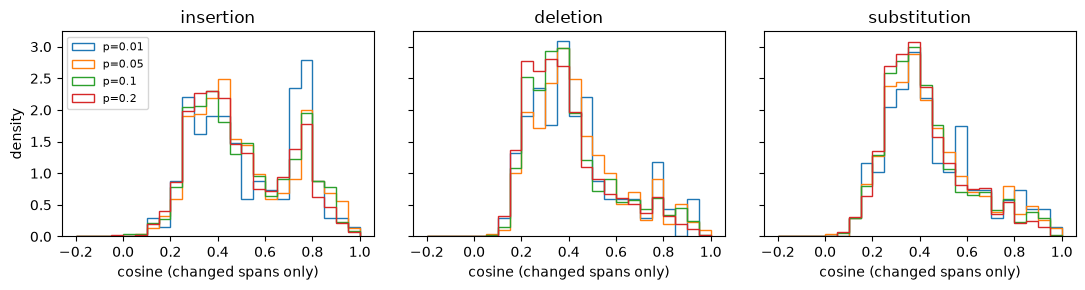

In [18]:
# what the cosines look like: the spread matters as much as the mean
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, op in zip(axes, ("ins", "del", "sub")):
    for pr in p2.rates:
        x = v[(v.op == op) & (v.p == pr) & v.text_changed].cosine
        ax.hist(x, bins=np.linspace(-0.2, 1, 25), histtype="step", label=f"p={pr}", density=True)
    ax.set_title({"ins": "insertion", "del": "deletion", "sub": "substitution"}[op]); ax.set_xlabel("cosine (changed spans only)")
axes[0].set_ylabel("density"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**How to read this (and what not to conclude).**

- Pairs whose text did not change have cosine exactly 1 and distance 0, so means over *all* valid pairs are pulled toward
  1 at low rates simply because few spans were hit. The histogram above is restricted to spans the noise changed.
- A low cosine means the pooled vector turned toward a different direction. It does **not** mean the meaning was lost,
  and a high cosine does not mean it was kept. This is the claim we keep separate from prediction in Workstream B.
- With one-piece spans (87% of the clean spans), cosine mostly compares one token's vector with the vector of its
  replacement pieces.
- Means are over valid pairs only. Always read them together with the undefined counts.

## 7. G6 — The 37-row static span audit

One row per condition (1 clean + 3 operations × 4 rates × 3 seeds). Every row reports **how many spans were selected, how many
gave a valid pair, and how many were undefined**, next to the means. Means are over valid pairs only.

Two kinds of mean are shown. `mean_cosine` is over all valid pairs, including spans the noise never touched (cosine exactly 1).
`mean_cosine_changed` is over valid pairs whose text was actually changed, which shows how far a span that *was* hit moved.

In [19]:
from src.geometry.drift import audit_table, seed_summary, plot_summary
audit = audit_table(pairs)
assert len(audit) == 37 and (audit.selected == 1000).all()
assert (audit.valid + audit.undefined == audit.selected).all() and audit.undefined.sum() == 62
assert audit.loc[audit.condition_id == "clean", ["mean_cosine", "mean_distance"]].round(12).values.tolist() == [[1.0, 0.0]]
audit.round(4)

,condition_id,operation,rate,seed,selected,valid,undefined,coverage,changed_spans,mean_cosine,mean_distance,mean_cosine_changed,mean_distance_changed
0,clean,clean,0.00,NaN,1000,1000,0,1.000,0,1.0000,0.0000,NaN,NaN
1,ins-p0.01-s11,insertion,0.01,11.0,1000,1000,0,1.000,39,0.9836,0.0363,0.5789,0.9298
2,ins-p0.01-s23,insertion,0.01,23.0,1000,1000,0,1.000,41,0.9794,0.0431,0.4967,1.0524
3,ins-p0.01-s47,insertion,0.01,47.0,1000,1000,0,1.000,56,0.9729,0.0566,0.5169,1.0106
4,ins-p0.05-s11,insertion,0.05,11.0,1000,1000,0,1.000,207,0.9065,0.2046,0.5483,0.9885
5,ins-p0.05-s23,insertion,0.05,23.0,1000,1000,0,1.000,215,0.8915,0.2266,0.4951,1.0539
6,ins-p0.05-s47,insertion,0.05,47.0,1000,1000,0,1.000,189,0.9053,0.1980,0.4990,1.0477
7,ins-p0.10-s11,insertion,0.10,11.0,1000,1000,0,1.000,372,0.8190,0.3810,0.5134,1.0243
8,ins-p0.10-s23,insertion,0.10,23.0,1000,1000,0,1.000,385,0.8104,0.3978,0.5075,1.0331
9,ins-p0.10-s47,insertion,0.10,47.0,1000,1000,0,1.000,379,0.8126,0.3939,0.5056,1.0393


## 8. G7 — Summaries across the three corruption seeds

For each operation and rate, the mean, minimum and maximum of the three seed-level results. The clean condition is one
dataset and is shown separately (cosine 1, distance 0), not as three runs.

**The min–max range is variation across three random corruptions of the same text.** It is not a confidence interval: no
model was retrained and no records were resampled.

In [20]:
summary = seed_summary(audit)
cols = ["operation", "rate", "valid_min", "undefined_max", "mean_cosine_mean", "mean_cosine_min", "mean_cosine_max",
        "mean_distance_mean", "mean_cosine_changed_mean"]
print("clean (single dataset): cosine = 1.000, distance = 0.000, 1000 valid / 0 undefined\n")
summary[cols].round(3)

clean (single dataset): cosine = 1.000, distance = 0.000, 1000 valid / 0 undefined



,operation,rate,valid_min,undefined_max,mean_cosine_mean,mean_cosine_min,mean_cosine_max,mean_distance_mean,mean_cosine_changed_mean
0,insertion,0.01,1000,0,0.979,0.973,0.984,0.045,0.531
1,insertion,0.05,1000,0,0.901,0.891,0.907,0.210,0.514
2,insertion,0.10,1000,0,0.814,0.810,0.819,0.391,0.509
3,insertion,0.20,1000,0,0.689,0.686,0.693,0.638,0.492
4,deletion,0.01,1000,0,0.974,0.971,0.978,0.052,0.427
5,deletion,0.05,998,2,0.883,0.881,0.886,0.237,0.435
6,deletion,0.10,994,6,0.782,0.772,0.790,0.432,0.412
7,deletion,0.20,983,17,0.638,0.626,0.645,0.708,0.391
8,substitution,0.01,1000,0,0.975,0.970,0.980,0.052,0.453
9,substitution,0.05,1000,0,0.882,0.878,0.891,0.235,0.441


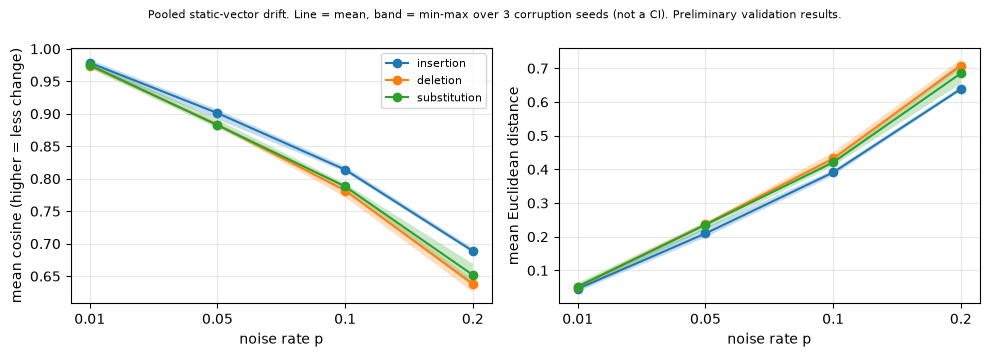

In [21]:
fig = plot_summary(summary, show=True)

**What this does and does not show (all preliminary validation results, one 22-record slice):**

- **Drift grows with the rate for all three operations.** Mean cosine falls from about 0.97–0.98 at p = 0.01 to about
  0.64–0.69 at p = 0.20, and mean distance rises from about 0.05 to about 0.64–0.71. The three seeds stay close together.
- **Most of that decline comes from how many spans were hit, not from each hit span moving further.** Among changed spans the
  mean cosine stays roughly flat as p grows (insertion about 0.49–0.53, deletion about 0.39–0.44, substitution about 0.42–0.45).
  Higher p mainly touches more spans.
- **Insertion drifts least per changed span.** This fits what G4 showed: an inserted letter often leaves the original
  letters in place, while deletion and substitution remove or replace them. We have not tested that explanation, and the
  difference between operations is modest.
- **Only deletion creates undefined pairs** (up to 17 of 1,000 spans per condition at p = 0.20). Deletion means therefore
  cover slightly fewer pairs.
- **No claim about meaning.** A lower cosine says the pooled static vector turned; it does not say meaning was lost, and a
  high cosine does not say it was kept. That question is for the prediction results.
- **Narrow sample.** 1,000 spans from 22 records (2 articles); 87% of clean spans are a single word piece.

## 9. G8 — Reproduce everything with the required script

The assignment asks for a program named `noise_vector_drift.py`. It runs the same pipeline end to end (spans, noisy twins, pooling,
metrics, audit, summary, figure) and writes the result files. Here we run it and check that it reproduces the tables above exactly.

In [22]:
import pandas.testing as pdt
from src.geometry.drift import run
out = run(verbose=False)                       # same code path as:  python noise_vector_drift.py
key = lambda d: d.sort_values("condition_id").reset_index(drop=True)
pdt.assert_frame_equal(key(out["audit"]), key(audit), check_exact=False, rtol=1e-9)
pdt.assert_frame_equal(out["summary"], summary, check_exact=False, rtol=1e-9)
print("script output == notebook tables (audit: 37 rows, summary: 12 rows)  -> OK")
print(json.dumps({k: out["info"][k] for k in ("spans_selected", "records_covered", "conditions", "pairs", "valid_pairs",
                                               "undefined_pairs", "identity_check_passed", "E_unchanged_after_run")}, indent=1))
for f in sorted(RESULTS_P3_DIR.rglob("*")):
    if f.is_file(): print(f"{f.relative_to(RESULTS_P3_DIR)!s:40} {f.stat().st_size:>9,} bytes")

script output == notebook tables (audit: 37 rows, summary: 12 rows)  -> OK
{
 "spans_selected": 1000,
 "records_covered": 22,
 "conditions": 37,
 "pairs": 37000,
 "valid_pairs": 36938,
 "undefined_pairs": 62,
 "identity_check_passed": true,
 "E_unchanged_after_run": true
}
ext/condition_rows.csv                      51,502 bytes
ext/ext_run_info.json                        3,227 bytes
ext/figures/ext_geometry_drift.png         149,543 bytes
ext/figures/ext_noise_loss.png             272,740 bytes
ext/figures/ext_operation_vs_med.png       132,807 bytes
ext/figures/ext_sweep_noise.png            156,191 bytes
ext/figures/ext_sweep_training.png         174,614 bytes
ext/geometry_audit.csv                       9,605 bytes
ext/geometry_summary.csv                     6,453 bytes
ext/noise_realized.csv                       7,592 bytes
ext/noise_summary.csv                       25,525 bytes
ext/operation_ranking.csv                    8,495 bytes
ext/reg/figures/reg_curves.png            

## Where we are

**Geometry workstream complete (G0–G8).** Frozen **E** (hash unchanged), 1,000 spans, verified noisy counterparts in 37
conditions, pooled vectors, cosine and distance for every valid pair, the 37-row audit, seed summaries and figure, and the
required script `noise_vector_drift.py` reproducing the tables.
Outputs are in `results/phase3/`. Remaining Phase 3 work belongs to Workstream B (next-token prediction) and the joint
n-gram comparison and write-up.

# Workstream B — Neural next-token prediction

Geometry measured how far a *static vector* moves. Now the second question: how does noise change **next-token prediction**?
These are different measurements, and a small vector change does not tell us how much a prediction changes.

**What the models do.** For every token in a record, the model sees the two tokens before it and gives a probability to the actual
next token. Two models, same network, different input:

| | input to the network | size |
|---|---|---|
| mean pooling | `(e1 + e2) / 2` | 768 numbers; word order is lost |
| concatenation | `[e1 ; e2]` | 1,536 numbers; word order is kept |

Then `h = ReLU(W1 x + b1)` with 64 hidden units, `z = W2 h + b2` over **K = 29,525** allowed outputs (the Assignment 2 output set:
the BERT vocabulary minus padding/CLS/SEP/MASK/unused entries, plus `[UNK]` and an end-of-record output), and a softmax. The embedding table **E** is
frozen: only `W1, b1, W2, b2` train. Settings are fixed by the assignment: Adam, learning rate 0.001, batch 128, at most 5 epochs, seed 101,
no dropout or weight decay. Both models train **once, on clean training text only**. The three corruption seeds only change the *evaluation* text.

The full run is `python neural_next_token.py` (about 4 to 7 minutes on a laptop CPU). This notebook reads its saved results, and re-computes some of them
from the saved weights to prove they match.

In [23]:
import torch
from src.phase2_config import load_phase2_config
from src.neural.run import build_output_space, load_records, load_control, summarise
from src.neural.data import encode_texts, BOS
from src.neural.model import NextTokenNet
from src.neural.evaluate import evaluate, to_tensors
from src.neural.figures import plot_training, plot_noise

cfgN = p3["neural"]
R = RESULTS_P3_DIR
neural = pd.read_csv(R / "neural_condition_rows.csv"); nsum = pd.read_csv(R / "neural_noise_summary.csv")
control = pd.read_csv(R / "ngram_control.csv"); hist = pd.read_csv(R / "neural_training_history.csv")
info = json.load(open(R / "neural_run_info.json"))
print("label:", info["label"]); print("results read from:", R)
print({k: info[k] for k in ("K_outputs", "torch", "device", "torch_threads", "deterministic_algorithms")})

label: preliminary validation results
results read from: /Users/samratrajsharma/Documents/School/Sem-3/NLP/Bert-Project/results/phase3
{'K_outputs': 29525, 'torch': '2.15.0', 'device': 'cpu', 'torch_threads': 1, 'deterministic_algorithms': True}


## 11. N0–N1 — Turning records into (context → next token) examples

For a record with pieces `w1 … wn` the examples are `(BOS,BOS)→w1`, `(BOS,w1)→w2`, …, `(w_{n-1},w_n)→EOS`. BOS means *beginning of sequence*: it only ever
appears as an **input**, and it is an all-zero vector (not a row of BERT's table). EOS means *end of sequence*: it is only ever an **output**. Every observed token
plus one EOS is scored, and the context starts fresh at each record: nothing is carried across records and no future tokens are used.

In [24]:
p2 = load_phase2_config()
pipe, vocab, vstats, hf_ids = build_output_space(p2)
train_rec, cond_rows = load_records()
inv_bert = {v: k for k, v in hf_ids.items()}
rec = train_rec[0]["text"]
toks = pipe.tokenize_batch([rec])[0]
seq = encode_texts([rec], pipe, vocab, hf_ids)
name_ctx = lambda i: "BOS" if i == BOS else inv_bert[i]
rows = [(name_ctx(a), name_ctx(b), vocab.tokens[t]) for (a, b), t in zip(seq.ctx[:5], seq.tgt[:5])]
rows += [(name_ctx(a), name_ctx(b), vocab.tokens[t]) for (a, b), t in zip(seq.ctx[-2:], seq.tgt[-2:])]
print(f"record {train_rec[0]['record_id']}: {len(toks)} pieces -> {seq.T} examples (pieces + one EOS)")
pd.DataFrame(rows, columns=["context 1", "context 2", "target"])

record wt2-train-000004: 105 pieces -> 106 examples (pieces + one EOS)


,context 1,context 2,target
0,BOS,BOS,the
1,BOS,the,game
2,the,game,began
3,game,began,development
4,began,development,in
5,',n,.
6,n,.,</s>


In [25]:
# the same targets as Assignment 2: counts must match exactly
ctrl = control.set_index("condition_id")["T"]
parity = neural[neural.model == "mean"].set_index("condition_id")["T"]
print("output set K                :", vocab.size, "(BERT vocab minus", vstats["excluded"], "excluded entries, plus the end-of-record output)")
print("training targets            :", json.load(open(DERIVED_P3_DIR / "neural_retained_records.json"))["train_targets"], "(500 clean training records)")
print("clean validation targets    :", int(parity["clean"]), " (Assignment 2 n-gram: ", int(ctrl["clean"]), ")")
print("all 37 conditions match the Assignment 2 target count:", bool((parity.sort_index() == ctrl.sort_index()).all()))
retained = json.load(open(DERIVED_P3_DIR / "neural_retained_records.json"))
print("retained records            :", retained["train_records"], "train,", retained["validation_records"], "validation; cap applied:", retained["cap_applied"])

output set K                : 29525 (BERT vocab minus 998 excluded entries, plus the end-of-record output)
training targets            : 35642 (500 clean training records)
clean validation targets    : 35971  (Assignment 2 n-gram:  35971 )
all 37 conditions match the Assignment 2 target count: True
retained records            : 500 train, 500 validation; cap applied: False


## 12. N2 — The two networks

Same layers, different input. **E** is held as a frozen lookup table: it is not a trainable parameter, is not in the optimizer and is not saved with the weights.
Concatenation has more input-layer weights (1,536 vs 768 inputs into the 64 hidden units), so any difference between the models cannot be credited only to word order.

In [26]:
rows = [{"model": m, "inputs m": 768 if m == "mean" else 1536, "trainable parameters": info["models"][m]["trainable"],
         "frozen (E)": info["models"][m]["frozen"], "formula 64m + 64 + 64K + K": 64*(768 if m == "mean" else 1536) + 64 + 64*vocab.size + vocab.size} for m in ("mean", "concat")]
pd.DataFrame(rows)

,model,inputs m,trainable parameters,frozen (E),formula 64m + 64 + 64K + K
0,mean,768,1968341,23440896,1968341
1,concat,1536,2017493,23440896,2017493


In [27]:
# Order test with the REAL trained weights: swap the two context tokens ("the game" vs "game the")
E_t = torch.from_numpy(np.array(E))
ids = lambda w: hf_ids[w]
ctx_a = torch.tensor([[ids("the"), ids("game")]]); ctx_b = torch.tensor([[ids("game"), ids("the")]])
for m in ("mean", "concat"):
    net = NextTokenNet(E_t, m, vocab.size, cfgN["hidden_size"])
    net.load_state_dict(torch.load(DERIVED_P3_DIR / "neural" / f"{m}_best.pt"))
    net.eval()
    with torch.no_grad():
        la, lb = net(ctx_a), net(ctx_b)
    top = lambda l: vocab.tokens[int(l.argmax())]
    print(f"{m:6}: largest change in the {vocab.size} scores after swapping = {float((la-lb).abs().max()):.4f};  top prediction {top(la)!r} vs {top(lb)!r}")

mean  : largest change in the 29525 scores after swapping = 0.0000;  top prediction 'the' vs 'the'
concat: largest change in the 29525 scores after swapping = 4.6449;  top prediction 'of' vs 'the'


The mean model gives *identical* scores for the swapped pair (it cannot see the order); the concatenation model does not. That is the one structural difference we are testing.

## 13. N3 — Training and picking the saved epoch

After each epoch we measure the loss on the **clean validation** records without updating anything, and keep the epoch with the lowest value (an exact tie keeps the earlier one).
Noisy results are never used to choose a model.

In [28]:
print("untrained validation loss:", {m: round(info["models"][m]["untrained_val_loss"], 3) for m in info["models"]}, " (uniform guessing = ln K = %.3f)" % np.log(vocab.size))
h = hist.copy(); h["kept"] = h.selected.map({True: "<- kept", False: ""})
h.round(4)[["model", "epoch", "train_loss", "val_loss", "val_accuracy", "kept"]]

untrained validation loss: {'mean': 10.297, 'concat': 10.289}  (uniform guessing = ln K = 10.293)


,model,epoch,train_loss,val_loss,val_accuracy,kept
0,mean,1,7.9131,7.5507,0.0866,
1,mean,2,6.7836,7.5032,0.0982,<- kept
2,mean,3,6.5746,7.5405,0.1120,
3,mean,4,6.4202,7.5793,0.1251,
4,mean,5,6.2969,7.6557,0.1274,
5,concat,1,7.6845,7.3197,0.1163,
6,concat,2,6.4703,7.2832,0.1381,<- kept
7,concat,3,6.1835,7.3472,0.1498,
8,concat,4,5.9862,7.4013,0.1567,
9,concat,5,5.8191,7.4707,0.1604,


In [29]:
fig = plot_training(hist)

**Reading this.** Training loss keeps falling, but validation loss is lowest at epoch 2 for both models and then rises: the networks start memorising the 500 training records
(35,642 targets against 29,525 possible outputs). Validation *accuracy* keeps creeping up even as the loss worsens, because the loss punishes confident wrong guesses.
The assignment says to select by validation loss, so epoch 2 is kept.

## 14. N4–N5 — Scoring 37 conditions with both models

Teacher-forced scoring: clean text is scored with clean contexts and clean targets, noisy text with noisy contexts and noisy targets, and the model's own guesses are never fed back.
Loss is **summed over every target in the condition** (including one EOS per record) and divided once by the target count: `H = S / T` in nats, `PP = exp(H)`,
accuracy = top-1 correct / T. Per-record perplexities are never averaged.

In [30]:
assert len(neural) == 74 and len(nsum) == 24
neural[neural.condition_id.isin(["clean", "ins-p0.10-s11", "del-p0.10-s11", "sub-p0.10-s11"])][
    ["model", "condition_id", "T", "H", "PP", "accuracy", "unk_share", "pieces_per_record"]].round(4).reset_index(drop=True)

,model,condition_id,T,H,PP,accuracy,unk_share,pieces_per_record
0,mean,clean,35971,7.5032,1813.8778,0.0982,0.0012,70.942
1,concat,clean,35971,7.2832,1455.6799,0.1381,0.0012,70.942
2,mean,ins-p0.10-s11,54940,8.7537,6334.0891,0.0558,0.0008,108.880
3,concat,ins-p0.10-s11,54940,8.6274,5582.5052,0.0743,0.0008,108.880
4,mean,del-p0.10-s11,44298,8.2417,3795.8478,0.0656,0.0010,87.596
5,concat,del-p0.10-s11,44298,8.1193,3358.7918,0.0902,0.0010,87.596
6,mean,sub-p0.10-s11,51454,8.6782,5873.3624,0.0566,0.0008,101.908
7,concat,sub-p0.10-s11,51454,8.5443,5137.5241,0.0780,0.0008,101.908


In [31]:
# Proof the saved weights reproduce the table: re-score three conditions from the saved models and compare with the CSV
chk = []
for m in ("mean", "concat"):
    net = NextTokenNet(E_t, m, vocab.size, cfgN["hidden_size"]); net.load_state_dict(torch.load(DERIVED_P3_DIR / "neural" / f"{m}_best.pt")); net.eval()
    for cid in ("clean", "ins-p0.10-s11", "del-p0.20-s47"):
        s_ = encode_texts([r["noisy_text"] for r in cond_rows[cid]], pipe, vocab, hf_ids)
        r_ = evaluate(net, *to_tensors(s_), chunk=cfgN["eval_chunk"])
        saved = neural[(neural.model == m) & (neural.condition_id == cid)].iloc[0]
        assert abs(r_["H"] - saved.H) < 1e-9 and abs(r_["accuracy"] - saved.accuracy) < 1e-12 and r_["T"] == saved["T"]
        chk.append((m, cid, round(r_["H"], 4), round(saved.H, 4)))
print("recomputed from saved weights == saved table for", len(chk), "model/condition pairs: OK")
pd.DataFrame(chk, columns=["model", "condition", "H recomputed", "H in table"])

recomputed from saved weights == saved table for 6 model/condition pairs: OK


,model,condition,H recomputed,H in table
0,mean,clean,7.5032,7.5032
1,mean,ins-p0.10-s11,8.7537,8.7537
2,mean,del-p0.20-s47,8.4901,8.4901
3,concat,clean,7.2832,7.2832
4,concat,ins-p0.10-s11,8.6274,8.6274
5,concat,del-p0.20-s47,8.4069,8.4069


In [32]:
# the 24-row noise summary: mean, min, max over the three corruption seeds; clean shown separately
cl = neural[neural.condition_id == "clean"].set_index("model")
print("clean (single dataset):", {m: (round(cl.H[m], 3), round(cl.PP[m], 1), round(cl.accuracy[m], 3)) for m in cl.index}, " (H, PP, accuracy)")
nsum[["model", "operation", "p", "H_mean", "H_min", "H_max", "PP_mean", "accuracy_mean", "accuracy_min", "accuracy_max", "dH_mean"]].round(3)

clean (single dataset): {'mean': (np.float64(7.503), np.float64(1813.9), np.float64(0.098)), 'concat': (np.float64(7.283), np.float64(1455.7), np.float64(0.138))}  (H, PP, accuracy)


,model,operation,p,H_mean,H_min,H_max,PP_mean,accuracy_mean,accuracy_min,accuracy_max,dH_mean
0,concat,insertion,0.01,7.496,7.488,7.501,1800.112,0.127,0.127,0.128,0.212
1,concat,insertion,0.05,8.132,8.118,8.140,3401.318,0.097,0.097,0.097,0.849
2,concat,insertion,0.10,8.624,8.618,8.627,5562.292,0.074,0.074,0.074,1.341
3,concat,insertion,0.20,9.167,9.151,9.177,9579.602,0.051,0.051,0.051,1.884
4,concat,deletion,0.01,7.415,7.408,7.420,1660.380,0.130,0.130,0.131,0.132
5,concat,deletion,0.05,7.806,7.803,7.809,2456.198,0.109,0.108,0.109,0.523
6,concat,deletion,0.10,8.108,8.095,8.119,3319.813,0.091,0.090,0.092,0.824
7,concat,deletion,0.20,8.402,8.396,8.407,4454.906,0.074,0.073,0.074,1.119
8,concat,substitution,0.01,7.494,7.486,7.502,1797.616,0.128,0.128,0.128,0.211
9,concat,substitution,0.05,8.104,8.101,8.107,3307.101,0.098,0.098,0.098,0.821


The min–max range is how much the result varies across **three random corruptions of the same text**. It is not a confidence interval: no model was retrained, so it says
nothing about variation across independently trained networks.

## 15. N6 — The Assignment 2 n-gram control

These 37 rows are the Assignment 2 interpolated WordPiece n-gram model (trained on the same 500 records), kept separate from the 74 neural rows. Its frozen interpolation weights
for this training set are `[1, 0, 0]`, which makes it the add-one **unigram** model: it ignores the two previous tokens entirely. We use it as-is because the assignment asks for the
Assignment 2 baseline.

In [33]:
csum = summarise(control, ["model", "operation", "p"], ["H", "PP", "dH"])
c0 = control[control.condition_id == "clean"].iloc[0]
print(f"clean: n-gram H = {c0.H:.3f} (PP {c0.PP:.0f})   mean-pool H = {cl.H['mean']:.3f} (PP {cl.PP['mean']:.0f})   concat H = {cl.H['concat']:.3f} (PP {cl.PP['concat']:.0f})")
assert len(control) == 37
cmp_ = nsum.pivot_table(index=["operation", "p"], columns="model", values="dH_mean").join(csum.set_index(["operation", "p"])["dH_mean"].rename("ngram"))
cmp_["neural worse than n-gram (mean | concat)"] = [f"{a > c} | {b > c}" for a, b, c in zip(cmp_["mean"], cmp_["concat"], cmp_["ngram"])]
cmp_.rename(columns={"mean": "mean-pool dH", "concat": "concat dH", "ngram": "n-gram dH"}).round(3)

clean: n-gram H = 7.549 (PP 1898)   mean-pool H = 7.503 (PP 1814)   concat H = 7.283 (PP 1456)


concat dH  mean-pool dH  n-gram dH  \
operation    p                                          
deletion     0.01      0.132         0.116      0.094   
             0.05      0.523         0.461      0.373   
             0.10      0.824         0.725      0.597   
             0.20      1.119         0.982      0.831   
insertion    0.01      0.212         0.194      0.151   
             0.05      0.849         0.785      0.608   
             0.10      1.341         1.249      0.970   
             0.20      1.884         1.783      1.385   
substitution 0.01      0.211         0.193      0.150   
             0.05      0.821         0.758      0.592   
             0.10      1.268         1.180      0.927   
             0.20      1.757         1.658      1.314   

                  neural worse than n-gram (mean | concat)  
operation    p                                              
deletion     0.01                              True | True  
             0.05                              True | True  
             0.10                              True | True  
             0.20                              True | True  
insertion    0.01                              True | True  
             0.05                              True | True  
             0.10                              True | True  
             0.20                              True | True  
substitution 0.01                              True | True  
             0.05                              True | True  
             0.10                              True | True  
             0.20                              True | True

In [34]:
fig = plot_noise(nsum, csum)

In [35]:
# absolute loss, not just change: where is each model better in raw loss on the noisy text?
absH = nsum.pivot_table(index=["operation", "p"], columns="model", values="H_mean").join(csum.set_index(["operation", "p"])["H_mean"].rename("ngram"))
absH["best (lowest loss)"] = absH[["mean", "concat", "ngram"]].idxmin(axis=1)
absH.round(3)

concat   mean  ngram best (lowest loss)
operation    p                                            
deletion     0.01   7.415  7.619  7.642             concat
             0.05   7.806  7.964  7.922             concat
             0.10   8.108  8.229  8.145             concat
             0.20   8.402  8.485  8.380              ngram
insertion    0.01   7.496  7.697  7.699             concat
             0.05   8.132  8.288  8.156             concat
             0.10   8.624  8.752  8.519              ngram
             0.20   9.167  9.286  8.933              ngram
substitution 0.01   7.494  7.697  7.698             concat
             0.05   8.104  8.261  8.141             concat
             0.10   8.551  8.683  8.475              ngram
             0.20   9.040  9.161  8.863              ngram

## 16. N7 — Tokenization diagnostics: why a number can move for a reason other than prediction quality

Loss measures how likely the model finds the *observed* text after tokenization. A lower noisy loss could come from easier targets or more unknown tokens, so always look at what the tokenizer did.

In [36]:
d = neural[neural.model == "mean"].copy()
diag = d.groupby(["operation", "p"], sort=False).agg(targets_T=("T", "mean"), pieces_per_record=("pieces_per_record", "mean"),
                                                       continuation_share=("continuation_share", "mean"), unk_share=("unk_share", "mean")).round(4)
print("All three operations INCREASE the number of targets T (typos break words into more word pieces: clean 71 pieces per record, up to 139 under 20% insertion). A noisy condition is therefore scored on a different, longer target sequence, so loss per target is not a like-for-like comparison with clean.")
print("noisy condition with lower loss than clean, any model:", bool((neural[neural.operation != "clean"].dH < 0).any()))
diag

All three operations INCREASE the number of targets T (typos break words into more word pieces: clean 71 pieces per record, up to 139 under 20% insertion). A noisy condition is therefore scored on a different, longer target sequence, so loss per target is not a like-for-like comparison with clean.
noisy condition with lower loss than clean, any model: False


targets_T  pieces_per_record  continuation_share  \
operation    p                                                         
clean        0.00  35971.0000            70.9420              0.0758   
insertion    0.01  38094.0000            75.1880              0.1280   
             0.05  46075.6667            91.1513              0.2807   
             0.10  55006.6667           109.0133              0.3986   
             0.20  70141.0000           139.2820              0.5293   
deletion     0.01  37125.0000            73.2500              0.1052   
             0.05  40897.6667            80.7953              0.1901   
             0.10  44282.3333            87.5647              0.2547   
             0.20  47421.6667            93.8433              0.3102   
substitution 0.01  37839.0000            74.6780              0.1221   
             0.05  44644.6667            88.2893              0.2574   
             0.10  51553.0000           102.1060              0.3579   
             0.20  62095.3333           123.1907              0.4678   

                   unk_share  
operation    p                
clean        0.00     0.0012  
insertion    0.01     0.0011  
             0.05     0.0009  
             0.10     0.0008  
             0.20     0.0006  
deletion     0.01     0.0012  
             0.05     0.0011  
             0.10     0.0010  
             0.20     0.0009  
substitution 0.01     0.0011  
             0.05     0.0010  
             0.10     0.0008  
             0.20     0.0007

## 17. What this shows, and what it does not (preliminary validation results)

- **Noise raises loss and lowers accuracy for both models, for all three operations, at every rate.** The effect grows with the rate. Clean: mean pooling PP ≈ 1,814 with 9.8% top-1 accuracy, concatenation PP ≈ 1,456 with 13.8%.
  At p = 0.20 insertion, loss rises by about 1.8 nats (accuracy falls to 3.9% and 5.1%).
- **Neither neural model deteriorates less than the n-gram control.** The increase in loss over each model's own clean result is larger for both neural models than for the control in every operation × rate cell.
  The control is a unigram, so it never depended on the previous tokens; the neural models also lose the quality of their context when the preceding tokens are corrupted. We have not isolated that explanation.
- **Concatenation is better in absolute loss and accuracy in every cell, but its loss rises slightly more than the mean model's.** Order information helps on clean text, and also gives noise more to disturb. Because concatenation has twice the input weights, we cannot credit this to word order alone.
- **Absolute loss tells a mixed story against the control.** Concatenation has the lowest loss in 7 of the 12 operation × rate cells and the n-gram control in the other 5 (mean pooling in none). The control wins at the heavier noise levels, so "which model is best" depends on the noise.
- **Insertion hurts most, deletion least** (at the same p), in loss for all models.
- **Overfitting limits all of this.** The clean validation loss is lowest after 2 epochs and the networks are fitted to only 500 records. This is a small, controlled study, not a demonstration of a neural advantage.
- **Variation across seeds is small, but it is only variation across three random corruptions** of one trained model per type, not a confidence interval.
- **Vector drift versus prediction change** (the assignment's third question, counterexamples) is the next step; this notebook only reports each side.

## Where we are

**Geometry (G0–G8) and neural prediction (N0–N7) are both done.** Outputs are in `results/phase3/` (neural: `neural_condition_rows.csv` 74 rows, `neural_noise_summary.csv` 24 rows,
`ngram_control.csv` 37 rows, `neural_vs_ngram_change.csv`, `neural_training_history.csv`, `neural_run_info.json`, figures) and `derived/phase3/` (retained records, best weights).
Still ahead in the assignment: interpret counterexamples where vector drift and prediction change disagree, cross-verify each other's code, and extend the paper.

# Extensions — beyond the Assignment 3 spec

Everything above is the required Assignment 3 work and is **not changed**. The sections below are team decisions that go further.
They read the required results and the extension run fails if it cannot reproduce them. Every table and figure here is labelled as an extension.

| Part | Question | Decision | Section |
|---|---|---|---|
| E1 | What happens past p = 0.20? | rates 0.01, 0.05, 0.10, 0.20 (saved files) + **0.30, 0.50, 0.70, 0.90** (new) | 19 |
| E2 | What is the *true* cost of noise? | **H_true = S / T_clean**: summed loss over the *clean* target count, the same denominator for every condition | 20 |
| E2 | Which operation hurts most? | ranked on every metric, at equal p and at equal edit distance | 21 |
| E3 | Do more hidden layers or more epochs help? | **1, 2, 3 hidden layers of width 64** (never wider), 30 epochs, everything else as Assignment 3 | 22 |
| E4 | One sentence, end to end | "A cow jumps over the fence", or any sentence you type | 23 |
| R1 | Can regularisation stop the overfitting? | dropout {0, 0.2, 0.5} × weight decay {0, 1e-5, 1e-4, 1e-3} on the same 500 records | 24 |
| R2 | Does more data help? | a 10K-record training chunk (36× the slice), networks and the n-gram both re-trained on it | 25 |
| — | Which network next? | recommendation | 26 |

Run: `python phase3_extensions.py` (about 15 minutes, most of it the sweep), which writes `results/phase3/ext/`. Settings: `extensions:` in `configs/phase3.yaml`.
Plan: `docs/assignment/Phase-3/PHASE3_PLAN.md` section 5.

## 18. E0 — Load the extension results and check them against the required results

In [37]:
from src.ext import figures as xfig
from src.ext.scoring import summarise as xsummarise
X = p3["extensions"]; RX = RESULTS_P3_DIR / "ext"
xinfo = json.load(open(RX / "ext_run_info.json"))
xrows = pd.read_csv(RX / "condition_rows.csv"); xsum = pd.read_csv(RX / "noise_summary.csv")
xgeo = pd.read_csv(RX / "geometry_summary.csv"); xaudit = pd.read_csv(RX / "geometry_audit.csv")
xnoise = pd.read_csv(RX / "noise_realized.csv"); xrank = pd.read_csv(RX / "operation_ranking.csv")
print("label   :", xinfo["label"])
print("device  :", xinfo["device"], "|", xinfo["note"])
print("conditions:", xinfo["conditions"], f"(1 clean + 3 operations x {len(X['noise']['rates'])} rates x 3 seeds)")
print("noise generator reproduces a saved Assignment 2 file exactly:", xinfo["generator_check"]["identical"])
for k, v in xinfo["parity"].items():
    print(f"reproduces required {k:22}:", v if isinstance(v, bool) else v["ok"], "" if isinstance(v, bool) else f"(max |dH| {v['max_abs_dH']:.1e}, tolerance {v['tolerance']:g})")

label   : extension beyond the Assignment 3 spec; preliminary validation results
device  : mps | GPU (mps): scoring matches cpu within 1e-7 nats; training repeats exactly run to run on this machine but follows a slightly different numerical path from cpu (1-layer validation loss within 0.008 nats of the cpu run over 5 epochs, same best epoch)
conditions: 73 (1 clean + 3 operations x 8 rates x 3 seeds)
noise generator reproduces a saved Assignment 2 file exactly: True
reproduces required neural_required_74    : True (max |dH| 8.6e-08, tolerance 0.0001)
reproduces required ngram_control_37      : True 
reproduces required geometry_audit_37     : True 


**GPU or CPU?** This laptop's GPU (Apple M4, PyTorch `mps`) trains one epoch in about 1.1 s against 3.4 s on one CPU thread, and scores about 4–5× faster.
Scoring on the GPU matches the CPU within 1e-7 nats (the 74 required rows above). GPU *training* repeats exactly from run to run on this machine,
but it follows a slightly different numerical path from the CPU: over 5 epochs the 1-layer models' validation loss stays within 0.008 nats of the CPU run and the same epoch is kept (section 22).
So the **required** results stay on the CPU, and the extensions use the GPU (`extensions.sweep.device`; it falls back to the CPU if no GPU is present).

## 19. E1 — Heavier noise: rates up to 0.90

The new rates use the same function, noise rule, seeds and per-record random key as Assignment 2. Before writing anything, the run regenerates one saved
Assignment 2 file in memory and requires it to match exactly. *p* is the chance that each eligible letter is edited, so p = 0.90 edits nine letters in ten.
The table shows what the noise actually did (realized rate, edit distance per clean character, records emptied by deletion).

In [38]:
nz = xnoise[xnoise.operation != "clean"]
tbl = nz.groupby(["operation", "p"], sort=False).agg(realized_rate=("realized_rate", "mean"), edit_distance_per_char=("normalized_med", "mean"),
                                                     empty_records=("empty_records", "max"))
pieces = xrows[xrows.model == "concat"].groupby(["operation", "p"], sort=False).agg(targets_T=("T", "mean"), pieces_per_record=("pieces_per_record", "mean"),
                                                                                   unk_share=("unk_share", "mean"))
tbl.join(pieces).round(3)

realized_rate  edit_distance_per_char  empty_records  \
operation    p                                                            
insertion    0.01          0.010                   0.008              0   
             0.05          0.050                   0.038              0   
             0.10          0.100                   0.076              0   
             0.20          0.201                   0.153              0   
             0.30          0.301                   0.229              0   
             0.50          0.500                   0.380              0   
             0.70          0.700                   0.532              0   
             0.90          0.900                   0.685              0   
deletion     0.01          0.010                   0.008              0   
             0.05          0.050                   0.038              0   
             0.10          0.099                   0.075              0   
             0.20          0.201                   0.153              0   
             0.30          0.301                   0.229              0   
             0.50          0.500                   0.381              0   
             0.70          0.699                   0.532              0   
             0.90          0.899                   0.684              0   
substitution 0.01          0.010                   0.008              0   
             0.05          0.050                   0.038              0   
             0.10          0.100                   0.076              0   
             0.20          0.200                   0.152              0   
             0.30          0.300                   0.229              0   
             0.50          0.500                   0.380              0   
             0.70          0.700                   0.532              0   
             0.90          0.900                   0.682              0   

                    targets_T  pieces_per_record  unk_share  
operation    p                                               
insertion    0.01   38094.000             75.188      0.001  
             0.05   46075.667             91.151      0.001  
             0.10   55006.667            109.013      0.001  
             0.20   70141.000            139.282      0.001  
             0.30   82888.000            164.776      0.001  
             0.50  103956.667            206.913      0.000  
             0.70  122617.333            244.235      0.000  
             0.90  139812.667            278.625      0.000  
deletion     0.01   37125.000             73.250      0.001  
             0.05   40897.667             80.795      0.001  
             0.10   44282.333             87.565      0.001  
             0.20   47421.667             93.843      0.001  
             0.30   47351.333             93.703      0.001  
             0.50   41978.333             82.957      0.001  
             0.70   32261.000             63.522      0.001  
             0.90   17944.000             34.888      0.002  
substitution 0.01   37839.000             74.678      0.001  
             0.05   44644.667             88.289      0.001  
             0.10   51553.000            102.106      0.001  
             0.20   62095.333            123.191      0.001  
             0.30   69493.667            137.987      0.001  
             0.50   79236.333            157.473      0.001  
             0.70   85688.333            170.377      0.001  
             0.90   90341.000            179.682      0.000

## 20. E2 — The true loss

`H = S / T` divides the summed loss by the number of **noisy** targets. Noise splits words into more pieces, so T grows and the extra cost gets spread over the extra pieces.
The true loss divides the same summed loss by the **clean** target count, which is 35,971 for every condition:

$$H_{true} = \frac{S}{T_{clean}} \qquad \text{(for the clean condition } H_{true} = H\text{)}$$

It answers: *how many nats does the model spend on this text in total, compared with the same text clean?* Accuracy stays per noisy target.

In [39]:
view = xsum[xsum.p.isin([0.0, 0.2, 0.5, 0.9])].copy()
view = view.pivot_table(index=["operation", "p"], columns="model", values=["H_mean", "H_true_mean"], sort=False)
view.columns = [f"{m} {'H' if v == 'H_mean' else 'true'}" for v, m in view.columns]
view[[c for m in ("mean", "concat", "ngram") for c in (f"{m} H", f"{m} true")]].round(2)

mean H  mean true  concat H  concat true  ngram H  \
operation    p                                                        
clean        0.0    7.50       7.50      7.28         7.28     7.55   
insertion    0.2    9.29      18.11      9.17        17.88     8.93   
             0.5   10.00      28.91      9.85        28.46     9.47   
             0.9   10.43      40.54     10.22        39.72     9.75   
deletion     0.2    8.48      11.19      8.40        11.08     8.38   
             0.5    8.42       9.83      8.39         9.79     8.42   
             0.9    7.05       3.52      7.04         3.51     7.30   
substitution 0.2    9.16      15.81      9.04        15.61     8.86   
             0.5    9.69      21.35      9.55        21.03     9.31   
             0.9    9.88      24.82      9.71        24.39     9.48   

                  ngram true  
operation    p                
clean        0.0        7.55  
insertion    0.2       17.42  
             0.5       27.36  
             0.9       37.91  
deletion     0.2       11.05  
             0.5        9.83  
             0.9        3.64  
substitution 0.2       15.30  
             0.5       20.50  
             0.9       23.82

In [40]:
fig = xfig.plot_noise_ext(xsum)

**Reading this (extension, preliminary validation results).**

- **H understates the damage, and the gap widens with p.** At p = 0.20 insertion, the concatenation model's H rises from 7.28 to 9.17 nats (+1.9), but its true loss rises to 17.9 (+10.6).
  At p = 0.90 insertion, H is 10.22, close to ln K = 10.29 (uniform guessing), and barely moving. Per target the model is already near chance, so H flattens.
  The true loss keeps climbing (39.7 nats per clean target) because the text keeps getting longer: 140k targets against 36k clean.
- **Insertion and substitution never level off in true loss; deletion turns around.** Deletion's true loss peaks near p = 0.30 (≈ 11.2) and then *falls*, below clean by p = 0.70 and to 3.5 at p = 0.90.
  Accuracy under deletion also climbs back (13.2% at p = 0.90 against 13.8% clean). The next cell shows why: deletion removes the text itself.
- **The n-gram control has the lowest true loss under heavy noise** for insertion and substitution, as it had for H at p ≥ 0.10 in section 15.

In [41]:
# why does heavy deletion look 'cheap'? fewer targets, and a growing share of them have no letters (punctuation, digits, end of record)
comp = []
for cid in ["clean", "del-p0.30-s11", "del-p0.70-s11", "del-p0.90-s11", "ins-p0.90-s11", "sub-p0.90-s11"]:
    from src.ext.conditions import load_ext_condition
    toks_ = pipe.tokenize_batch([r["noisy_text"] for r in load_ext_condition(cid, p2, p3)])
    T_ = sum(len(t) + 1 for t in toks_); letters = sum(1 for t in toks_ for x in t if any(c.isalpha() for c in x))
    comp.append({"condition": cid, "targets T": T_, "T / T_clean": T_ / 35971, "share of targets with no letter (incl. EOS)": (T_ - letters) / T_})
pd.DataFrame(comp).round(3)

,condition,targets T,T / T_clean,share of targets with no letter (incl. EOS)
0,clean,35971,1.000,0.200
1,del-p0.30-s11,47370,1.317,0.153
2,del-p0.70-s11,32259,0.897,0.226
3,del-p0.90-s11,17987,0.500,0.405
4,ins-p0.90-s11,139654,3.882,0.052
5,sub-p0.90-s11,90369,2.512,0.081


At 90% deletion only half as many targets are left, and 40% of them are punctuation, digits or end-of-record, against 20% in clean text.
Those are tokens the noise rule cannot touch and the models predict well. **A lower loss here means there is less text left to predict, not that the model is robust.**
Loss cannot tell "the text was preserved" from "the text was removed". This is a counterexample to reading low loss as robustness, in the spirit of Assignment 3 §17.

## 21. E2 — Which operation hurts most?

For each model and rate the three operations are ordered from most to least harmful (`ins > sub > del` means insertion did the most damage).
Prediction metrics: true loss, loss per noisy target, accuracy. Geometry: mean cosine (lower = more drift) and mean distance.

In [42]:
rk = xrank.copy()
rk["metric"] = rk.model + " | " + rk.metric.str.replace("_mean", "")
rk.pivot(index="p", columns="metric", values="order (most > least)")[[
    "concat | H_true", "mean | H_true", "ngram | H_true", "concat | H", "concat | accuracy", "geometry | mean_cosine", "geometry | mean_distance"]]

metric,concat | H_true,mean | H_true,ngram | H_true,concat | H,concat | accuracy,geometry | mean_cosine,geometry | mean_distance
p,,,,,,,
0.01,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,del > sub > ins,sub > del > ins
0.05,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,sub > del > ins,del > sub > ins
0.10,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,del > sub > ins,del > sub > ins
0.20,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,del > sub > ins,del > sub > ins
0.30,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,del > sub > ins,del > sub > ins
0.50,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,del > sub > ins,del > sub > ins
0.70,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,del > sub > ins,del > sub > ins
0.90,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,ins > sub > del,del > sub > ins,del > sub > ins


Equal *p* is not equal damage. Each operation causes a slightly different edit distance per character, so the next figure puts every point at the edit distance it
actually caused (x axis). An operation whose curve is higher at the same x does more harm per character edited.

In [43]:
fig = xfig.plot_operation_vs_med(xsum, xgeo, xnoise)

In [44]:
fig = xfig.plot_geometry_ext(xgeo)
xgeo[xgeo.rate >= 0.3][["operation", "rate", "valid_min", "undefined_max", "mean_cosine_mean", "mean_distance_mean", "mean_cosine_changed_mean"]].round(3)

,operation,rate,valid_min,undefined_max,mean_cosine_mean,mean_distance_mean,mean_cosine_changed_mean
4,insertion,0.3,1000,0,0.608,0.793,0.474
5,insertion,0.5,1000,0,0.504,0.967,0.444
6,insertion,0.7,1000,0,0.449,1.053,0.428
7,insertion,0.9,1000,0,0.414,1.104,0.410
12,deletion,0.3,964,36,0.539,0.889,0.374
13,deletion,0.5,903,97,0.414,1.100,0.340
14,deletion,0.7,758,242,0.343,1.214,0.307
15,deletion,0.9,385,615,0.296,1.268,0.285
20,substitution,0.3,1000,0,0.560,0.851,0.400
21,substitution,0.5,1000,0,0.448,1.048,0.382


**Which operation hurts most? It depends on what you measure (extension, preliminary validation results).**

- **For prediction: insertion > substitution > deletion**, in true loss for all three models at every rate from 0.01 to 0.90, and in H and accuracy for the concatenation model.
  Insertion adds letters, so it creates the most new word pieces to predict.
- **For static vector drift the order flips: deletion moves vectors the most and insertion the least** (lowest mean cosine and largest distance from p = 0.10 up).
  An inserted letter leaves the original letters in place, so the pieces stay closer to the clean word's pieces; deletion removes them.
- **So the operation with the smallest vector drift (insertion) is the one that hurts prediction most, and the one with the largest drift (deletion) hurts it least.**
  This is the clearest counterexample in the study to a simple "small drift means robust prediction" story (Assignment 3 §16). Part of deletion's advantage is the shrinking-text effect above, so it is not evidence that deletion is harmless.
- **At equal actual damage (the edit-distance figure)** the three operations caused almost the same edit distance per character at each p, so the ranking does not come from one operation simply editing more.
- **Coverage matters at high deletion rates.** At p = 0.90 deletion, 615 of the 1,000 spans are fully deleted and undefined; its geometry means cover only the 385 spans that survive.
- Cosine among *changed* spans drifts down slowly with p for every operation (insertion 0.53 → 0.41), so heavier noise does move each hit span further, not only more spans.

## 22. E3 — More hidden layers, more epochs

Same data, optimizer, learning rate, batch size, seed and selection rule as Assignment 3. Only the number of hidden layers (1, 2, 3, all 64 wide) and the epoch limit (30) change.
The epoch kept is still the one with the lowest **clean validation** loss, and that model is then scored on all 73 conditions.

In [45]:
xh = pd.read_csv(RX / "sweep_history.csv"); xss = pd.read_csv(RX / "sweep_noise_summary.csv")
best = []
for (m, n), g in xh.groupby(["model", "n_layers"]):
    s = g[g.selected].iloc[0]; last = g.iloc[-1]; inf = xinfo["sweep"][f"{m}_L{n}"]
    best.append({"model": m, "hidden layers": n, "trainable params": inf["trainable"], "best epoch": int(s.epoch),
                 "best val loss": s.val_loss, "val acc @best": s.val_accuracy, "val loss @30": last.val_loss,
                 "train loss @30": last.train_loss, "val acc @30": last.val_accuracy, "train s": inf["train_seconds"]})
pd.DataFrame(best).round(4)

,model,hidden layers,trainable params,best epoch,best val loss,val acc @best,val loss @30,train loss @30,val acc @30,train s
0,concat,1,2017493,2,7.2828,0.1379,11.3006,2.9539,0.1563,76.9
1,concat,2,2021653,2,7.3252,0.1279,14.1343,3.1358,0.1489,67.8
2,concat,3,2025813,2,7.3084,0.1255,15.1106,3.4498,0.1446,66.9
3,mean,1,1968341,2,7.5045,0.0982,9.6995,4.3187,0.1487,60.7
4,mean,2,1972501,2,7.4805,0.1036,12.3599,4.2244,0.1409,64.1
5,mean,3,1976661,2,7.5175,0.0957,12.6861,4.3957,0.1361,66.8


In [46]:
fig = xfig.plot_sweep_training(xh)

In [47]:
# where does it flatten? training loss: relative drop per epoch (levelling off = under 1% per epoch); validation: rise since the best epoch
lvl = []
for (m, n), g in xh.groupby(["model", "n_layers"]):
    g = g.set_index("epoch"); rel = -g.train_loss.diff() / g.train_loss.shift()
    flat = rel[rel < 0.01].index.min()
    lvl.append({"model": m, "hidden layers": n, "train drop epoch 2->3": rel[3], "train drop epoch 29->30": rel[30],
                "train levels off (<1%/epoch)": "not within 30 epochs" if pd.isna(flat) else f"epoch {flat}",
                "val loss rise, best -> epoch 30 (nats)": g.val_loss[30] - g.val_loss.min()})
pd.DataFrame(lvl).round(3)

,model,hidden layers,train drop epoch 2->3,train drop epoch 29->30,train levels off (<1%/epoch),"val loss rise, best -> epoch 30 (nats)"
0,concat,1,0.045,0.018,not within 30 epochs,4.018
1,concat,2,0.050,0.019,not within 30 epochs,6.809
2,concat,3,0.045,0.020,not within 30 epochs,7.802
3,mean,1,0.031,0.014,not within 30 epochs,2.195
4,mean,2,0.029,0.015,not within 30 epochs,4.879
5,mean,3,0.028,0.014,not within 30 epochs,5.169


**Reading this (extension, preliminary validation results).**

- **Every variant is best at epoch 2: 1, 2 or 3 hidden layers, mean or concatenation.** More epochs only make clean validation loss worse.
  For the 1-layer concatenation model, validation loss goes 7.28 (epoch 2) → 7.47 (5) → 8.10 (10) → 11.30 (30), while training loss falls 6.48 → 2.95. That is memorisation of the 500 training records.
- **Training loss never levels off within 30 epochs.** It still drops 1.3–2.0% per epoch at epoch 30 and is slowing, so it would level off only some way past 30 epochs, as the training set becomes memorised. Validation loss flattens at epoch 2, at its minimum, and then climbs.
- **Depth does not help.** The best clean validation loss stays within 0.04 nats of the 1-layer model (concatenation: 7.283 / 7.325 / 7.308 for 1 / 2 / 3 layers; mean: 7.505 / 7.480 / 7.518).
  The extra 64×64 layers add only about 4k parameters each; almost all ~2M parameters sit in the 64 → 29,525 output layer, and the bottleneck is 500 training records, not depth.
- **Deeper networks overfit faster** (validation loss at epoch 30: 11.3 vs 14.1 vs 15.1 for concatenation) and end with lower validation accuracy.
- **Depth does not change robustness to noise.** The true-loss increase is nearly identical for 1, 2 and 3 layers at every rate (differences ≤ 0.7 nats against increases of up to 33 nats, with no consistent direction).
- **Validation accuracy peaks much later (epochs 11–28) than loss.** Accuracy only counts the top guess, while loss also punishes confident wrong guesses, so the two can disagree. The assignment selects by loss.
- **What would help instead:** more training data (`train_full` exists from Phase 2), or regularisation (dropout or weight decay, which the assignment fixes at 0). We have not run either.

In [48]:
# GPU vs CPU: the 1-layer sweep model's first 5 epochs next to the required CPU run (same settings otherwise)
cmp1 = xh[xh.n_layers == 1].merge(hist, on=["model", "epoch"], suffixes=("_gpu_sweep", "_cpu_required"))
cmp1["|diff|"] = (cmp1.val_loss_gpu_sweep - cmp1.val_loss_cpu_required).abs()
cmp1[["model", "epoch", "val_loss_gpu_sweep", "val_loss_cpu_required", "|diff|"]].round(6)

,model,epoch,val_loss_gpu_sweep,val_loss_cpu_required,|diff|
0,mean,1,7.550683,7.550711,0.000028
1,mean,2,7.504457,7.503222,0.001235
2,mean,3,7.541684,7.540526,0.001158
3,mean,4,7.577227,7.579258,0.002030
4,mean,5,7.652834,7.655662,0.002828
5,concat,1,7.322945,7.319750,0.003195
6,concat,2,7.282758,7.283228,0.000470
7,concat,3,7.355090,7.347248,0.007842
8,concat,4,7.399502,7.401285,0.001783
9,concat,5,7.471329,7.470709,0.000620


In [49]:
# does depth change robustness? true-loss increase over each variant's own clean loss, mean over seeds
rob = xss[xss.operation != "clean"].pivot_table(index=["operation", "p"], columns=["model", "n_layers"], values="dH_true_mean", sort=False)
rob.round(2)

model             concat                 mean              
n_layers               1      2      3      1      2      3
operation    p                                             
insertion    0.01   0.65   0.66   0.66   0.65   0.65   0.65
             0.05   3.13   3.18   3.16   3.11   3.09   3.09
             0.10   5.90   5.99   5.96   5.88   5.84   5.84
             0.20  10.59  10.75  10.68  10.61  10.49  10.49
             0.30  14.56  14.78  14.69  14.64  14.44  14.45
             0.50  21.18  21.51  21.35  21.42  21.07  21.07
             0.70  27.05  27.47  27.25  27.46  26.96  26.95
             0.90  32.45  32.96  32.67  33.05  32.39  32.36
deletion     0.01   0.37   0.37   0.37   0.36   0.36   0.36
             0.05   1.59   1.60   1.60   1.55   1.55   1.55
             0.10   2.70   2.72   2.72   2.63   2.62   2.63
             0.20   3.79   3.82   3.83   3.68   3.66   3.68
             0.30   3.89   3.92   3.94   3.76   3.72   3.75
             0.50   2.51   2.52   2.57   2.32   2.29   2.31
             0.70  -0.09  -0.10  -0.05  -0.31  -0.32  -0.32
             0.90  -3.77  -3.81  -3.77  -3.99  -3.98  -4.00
substitution 0.01   0.60   0.61   0.61   0.59   0.59   0.59
             0.05   2.77   2.81   2.80   2.75   2.74   2.74
             0.10   4.97   5.04   5.03   4.94   4.91   4.92
             0.20   8.32   8.44   8.41   8.32   8.22   8.24
             0.30  10.66  10.81  10.77  10.69  10.53  10.56
             0.50  13.75  13.93  13.89  13.85  13.58  13.63
             0.70  15.74  15.94  15.90  15.91  15.56  15.62
             0.90  17.11  17.31  17.29  17.32  16.92  16.99

In [50]:
fig = xfig.plot_sweep_noise(xss)

## 23. E4 — Follow one sentence through the whole pipeline

**Change the inputs in the next cell and re-run it**, or use the form in the cell after it (type, then press *Run*). From a terminal:
`python phase3_extensions.py trace "A cow jumps over the fence" --word cow --custom "A cwo jumps ovr the fence"`.

- `SENTENCE`: any text. It goes through the same noise rule, tokenizer, frozen table **E**, the two required networks and the n-gram control.
- `FOCUS_WORD`: gets one edit of each kind on the same letter (cow → coow / cw / cpw), so the three operations are compared on exactly the same position. `None` skips this.
- `RATES`, `SEED`: random noise at each rate (the real noise function; same seed → same noisy text).
- `CUSTOM`: your own noisy versions, `{"name": "text"}`.
- `DETAIL`: which variants get the full per-token table (context → target, loss, top-3 guesses).

This is an **illustration, not evidence**. The networks learned from 500 WikiText records, so their guesses on a sentence like this are mostly frequent tokens.

In [51]:
from src.ext.trace import load_context, trace, show, widget
tctx = load_context()                     # loads the tokenizer, E, both required networks and the n-gram once

SENTENCE   = X["trace"]["sentence"]       # "A cow jumps over the fence"
FOCUS_WORD = "cow"
RATES      = X["trace"]["rates"]          # [0.1, 0.3, 0.5, 0.9]
SEED       = X["trace"]["seed"]
CUSTOM     = {"my typo": "A cwo jumps ovr the fence"}
DETAIL     = ["clean", "controlled insertion on 'cow'", "substitution p=0.5"]

tr_ = trace(SENTENCE, tctx, RATES, SEED, FOCUS_WORD, CUSTOM)
show(tr_, [d for d in DETAIL if d in tr_["tokens"]])

**Summary per variant** (H = loss per noisy target; true loss = summed loss / clean target count)

,variant,text,edits,MED,MED per char,pieces,mean word cosine,T,mean H,mean true loss,mean acc,concat H,concat true loss,concat acc,ngram H,ngram true loss
0,clean,A cow jumps over the fence,0.0,0,0.000,6,1.000,7,8.158,8.158,0.143,8.188,8.188,0.143,7.589,7.589
1,controlled insertion on 'cow',A coow jumps over the fence,1.0,1,0.038,7,0.907,8,8.024,9.170,0.125,7.963,9.100,0.125,7.610,8.697
2,controlled deletion on 'cow',A cw jumps over the fence,1.0,1,0.038,6,0.903,7,8.200,8.200,0.143,8.178,8.178,0.143,7.589,7.589
3,controlled substitution on 'cow',A cpw jumps over the fence,1.0,1,0.038,7,0.903,8,8.380,9.577,0.125,8.241,9.418,0.125,7.889,9.016
4,insertion p=0.1,A cow jumps over the fence,0.0,0,0.000,6,1.000,7,8.158,8.158,0.143,8.188,8.188,0.143,7.589,7.589
5,insertion p=0.3,A cow jumapvs obver the fencqe,4.0,4,0.154,13,0.695,14,9.932,19.864,0.000,10.165,20.330,0.000,9.050,18.100
6,insertion p=0.5,Ai covw jumxpjs ovnegrh thde fence,8.0,8,0.308,15,0.453,16,10.470,23.932,0.000,10.296,23.534,0.000,9.903,22.636
7,insertion p=0.9,Ay ceolwm jnukmnpusj opvzerl twhey freinncjei,19.0,19,0.731,24,0.463,25,10.520,37.572,0.000,10.292,36.756,0.000,9.608,34.315
8,deletion p=0.1,cow jumps over te fence,2.0,2,0.077,5,0.846,6,9.156,7.848,0.000,9.343,8.008,0.000,8.985,7.701
9,deletion p=0.3,cow jmps ver t fece,6.0,6,0.231,8,0.480,9,9.238,11.877,0.000,9.689,12.457,0.000,9.198,11.826


**Per-word static-vector drift** (frozen BERT table, mean of piece vectors)

,variant,clean word,noisy word,clean pieces,noisy pieces,cosine,distance,note
7,controlled insertion on 'cow',cow,coow,cow,co ##ow,0.443,1.281,
13,controlled deletion on 'cow',cow,cw,cow,cw,0.421,1.528,
19,controlled substitution on 'cow',cow,cpw,cow,cp ##w,0.418,1.338,
32,insertion p=0.3,jumps,jumapvs,jumps,ju ##ma ##p ##vs,0.529,1.162,
33,insertion p=0.3,over,obver,over,ob ##ver,0.219,1.363,
35,insertion p=0.3,fence,fencqe,fence,fen ##c ##q ##e,0.421,1.170,
36,insertion p=0.5,A,Ai,a,ai,0.211,1.430,
37,insertion p=0.5,cow,covw,cow,co ##v ##w,0.409,1.287,
38,insertion p=0.5,jumps,jumxpjs,jumps,ju ##mx ##p ##js,0.574,1.142,
39,insertion p=0.5,over,ovnegrh,over,o ##vn ##eg ##rh,0.225,1.336,


**Per-token predictions: clean** (loss in nats; top guesses with probability)

,context,target,mean loss,mean top-3,concat loss,concat top-3,ngram loss,ngram top-3
0,BOS BOS,a,7.15,"the 0.001, . 0.001, </s> 0.001",7.20,"the 0.001, in 0.001, a 0.001",4.78,"the 0.032, , 0.026, . 0.021"
1,BOS a,cow,11.32,"the 0.004, of 0.002, . 0.002",11.62,"the 0.002, a 0.001, @ 0.001",11.08,"the 0.032, , 0.026, . 0.021"
2,a cow,jumps,10.74,", 0.025, . 0.021, of 0.017",11.37,"of 0.063, , 0.054, . 0.045",10.39,"the 0.032, , 0.026, . 0.021"
3,cow jumps,over,7.15,", 0.124, . 0.086, of 0.043",7.05,", 0.110, . 0.080, of 0.032",7.47,"the 0.032, , 0.026, . 0.021"
4,jumps over,the,2.58,"the 0.076, , 0.067, . 0.052",1.31,"the 0.271, a 0.048, and 0.023",3.44,"the 0.032, , 0.026, . 0.021"
5,over the,fence,13.32,"the 0.051, of 0.015, , 0.014",12.75,"the 0.014, a 0.006, was 0.006",11.08,"the 0.032, , 0.026, . 0.021"
6,the fence,</s>,4.85,", 0.029, . 0.024, of 0.021",6.01,"of 0.092, , 0.062, . 0.061",4.87,"the 0.032, , 0.026, . 0.021"


**Per-token predictions: controlled insertion on 'cow'** (loss in nats; top guesses with probability)

,context,target,mean loss,mean top-3,concat loss,concat top-3,ngram loss,ngram top-3
0,BOS BOS,a,7.15,"the 0.001, . 0.001, </s> 0.001",7.20,"the 0.001, in 0.001, a 0.001",4.78,"the 0.032, , 0.026, . 0.021"
1,BOS a,co,8.29,"the 0.004, of 0.002, . 0.002",8.48,"the 0.002, a 0.001, @ 0.001",8.45,"the 0.032, , 0.026, . 0.021"
2,a co,##ow,9.84,"the 0.015, , 0.013, . 0.012",9.93,"of 0.025, , 0.019, . 0.019",10.39,"the 0.032, , 0.026, . 0.021"
3,co ##ow,jumps,11.03,", 0.049, . 0.038, of 0.022",10.89,", 0.044, . 0.030, and 0.013",10.39,"the 0.032, , 0.026, . 0.021"
4,##ow jumps,over,7.14,", 0.114, . 0.078, of 0.039",7.13,", 0.148, . 0.109, to 0.038",7.47,"the 0.032, , 0.026, . 0.021"
5,jumps over,the,2.58,"the 0.076, , 0.067, . 0.052",1.31,"the 0.271, a 0.048, and 0.023",3.44,"the 0.032, , 0.026, . 0.021"
6,over the,fence,13.32,"the 0.051, of 0.015, , 0.014",12.75,"the 0.014, a 0.006, was 0.006",11.08,"the 0.032, , 0.026, . 0.021"
7,the fence,</s>,4.85,", 0.029, . 0.024, of 0.021",6.01,"of 0.092, , 0.062, . 0.061",4.87,"the 0.032, , 0.026, . 0.021"


**Per-token predictions: substitution p=0.5** (loss in nats; top guesses with probability)

,context,target,mean loss,mean top-3,concat loss,concat top-3,ngram loss,ngram top-3
0,BOS BOS,i,8.19,"the 0.001, . 0.001, </s> 0.001",8.25,"the 0.001, in 0.001, a 0.001",7.53,"the 0.032, , 0.026, . 0.021"
1,BOS i,ho,8.39,"the 0.007, . 0.004, , 0.004",8.35,"the 0.005, , 0.005, . 0.005",9.01,"the 0.032, , 0.026, . 0.021"
2,i ho,##k,9.57,", 0.017, . 0.015, the 0.014",9.46,", 0.005, . 0.004, of 0.003",10.39,"the 0.032, , 0.026, . 0.021"
3,ho ##k,j,8.99,", 0.030, . 0.025, of 0.017",8.93,", 0.040, . 0.029, and 0.020",9.48,"the 0.032, , 0.026, . 0.021"
4,##k j,##mm,9.45,", 0.028, . 0.024, of 0.015",9.28,", 0.041, . 0.035, of 0.016",10.39,"the 0.032, , 0.026, . 0.021"
5,j ##mm,##ps,9.51,", 0.044, . 0.034, of 0.018",9.19,", 0.028, . 0.024, of 0.010",10.39,"the 0.032, , 0.026, . 0.021"
6,##mm ##ps,g,8.60,", 0.088, . 0.063, of 0.032",8.95,", 0.079, . 0.060, and 0.029",8.89,"the 0.032, , 0.026, . 0.021"
7,##ps g,##v,8.55,", 0.042, . 0.035, of 0.021",8.76,". 0.035, , 0.032, and 0.018",9.48,"the 0.032, , 0.026, . 0.021"
8,g ##v,##pt,10.81,", 0.029, . 0.025, of 0.016",10.62,", 0.020, . 0.017, of 0.009",10.39,"the 0.032, , 0.026, . 0.021"
9,##v ##pt,ink,9.91,", 0.037, . 0.029, of 0.016",9.91,", 0.018, . 0.017, of 0.007",9.99,"the 0.032, , 0.026, . 0.021"


In [52]:
widget(tctx, SENTENCE)                    # interactive form (needs a live kernel; the static output above always works)

## 24. R1 — Can regularisation stop the overfitting?

Sections 13 and 22 show the networks memorising the 500 training records after epoch 2. Two standard fixes, tried on the **same** data so the effect is regularisation alone:

- **Dropout** {0, 0.2, 0.5}: during training, randomly switch off that share of hidden units after every hidden ReLU, so the network cannot rely on any single unit.
- **Weight decay** {0, 1e-5, 1e-4, 1e-3}: Adam's own L2 penalty, which pulls weights toward zero, so the optimizer is unchanged.

Every combination, for both models, at 1 hidden layer (depth made no difference in section 22), 30 epochs, everything else as Assignment 3. The setting with the lowest clean validation loss
wins per model; it is then re-run at 2 and 3 layers and scored on all 73 noise conditions. Picking on the validation records and reporting on them is optimistic; the test split stays sealed.
Run: `python phase3_extensions.py regularise` (about 35 minutes on the GPU).

In [53]:
RG = RX / "reg"
rgrid = pd.read_csv(RG / "reg_grid.csv"); rbest = pd.read_csv(RG / "reg_best.csv"); rhist = pd.read_csv(RG / "reg_history.csv")
rsum = pd.read_csv(RG / "reg_noise_summary.csv")
show_cols = ["model", "n_layers", "dropout", "weight_decay", "best_epoch", "best_val_loss", "val_acc_at_best", "val_loss_at_30", "val_rise_after_best"]
print("winners (lowest clean validation loss, 1 hidden layer):")
print(rbest[["model", "dropout", "weight_decay", "best_epoch", "best_val_loss", "val_acc_at_best"]].round(4).to_string(index=False))
rgrid[rgrid.n_layers == 1][show_cols].sort_values(["model", "best_val_loss"]).round(4).reset_index(drop=True)

winners (lowest clean validation loss, 1 hidden layer):
 model  dropout  weight_decay  best_epoch  best_val_loss  val_acc_at_best
  mean      0.2        0.0001          29         7.0242           0.1431
concat      0.5        0.0001          30         6.7757           0.1621


,model,n_layers,dropout,weight_decay,best_epoch,best_val_loss,val_acc_at_best,val_loss_at_30,val_rise_after_best
0,concat,1,0.5,0.0001,30,6.7757,0.1621,6.7757,0.0000
1,concat,1,0.5,0.0000,19,6.8220,0.1683,6.8967,0.0747
2,concat,1,0.2,0.0001,23,6.8388,0.1703,6.8572,0.0185
3,concat,1,0.0,0.0010,29,6.8957,0.1579,6.9037,0.0080
4,concat,1,0.2,0.0010,29,6.9189,0.1504,6.9294,0.0105
5,concat,1,0.2,0.0000,7,6.9445,0.1604,7.3362,0.3917
6,concat,1,0.0,0.0001,15,6.9519,0.1703,7.0486,0.0967
7,concat,1,0.5,0.0010,29,6.9729,0.1386,6.9821,0.0092
8,concat,1,0.0,0.0000,4,7.0387,0.1572,7.9802,0.9415
9,concat,1,0.5,0.0000,3,7.2324,0.1363,8.6208,1.3884


In [54]:
fig = xfig.plot_reg_grid(rgrid)

In [55]:
fig = xfig.plot_reg_curves(rhist, rbest)

In [56]:
# the winners at 2 and 3 hidden layers
rgrid.merge(rbest[["model", "dropout", "weight_decay"]], on=["model", "dropout", "weight_decay"])[show_cols].sort_values(["model", "n_layers"]).round(4)

,model,n_layers,dropout,weight_decay,best_epoch,best_val_loss,val_acc_at_best,val_loss_at_30,val_rise_after_best
1,concat,1,0.5,0.0001,30,6.7757,0.1621,6.7757,0.0000
4,concat,2,0.5,0.0001,16,6.8957,0.1411,6.9228,0.0271
5,concat,3,0.5,0.0001,24,6.9867,0.1352,7.0229,0.0362
0,mean,1,0.2,0.0001,29,7.0242,0.1431,7.0415,0.0173
2,mean,2,0.2,0.0001,13,7.1753,0.1320,7.2899,0.1146
3,mean,3,0.2,0.0001,21,7.2136,0.1337,7.2797,0.0660


In [57]:
# robustness: does the regularised model's loss rise less under noise? (true loss, 1 layer, mean over 3 seeds)
k = rsum[(rsum.n_layers == 1) & (rsum.operation != "clean") & rsum.p.isin([0.05, 0.2, 0.5, 0.9])].copy()
k["setting"] = np.where((k.dropout == 0) & (k.weight_decay == 0), "none", "best")
tab = k.pivot_table(index=["operation", "p"], columns=["model", "setting"], values=["H_true_mean", "dH_true_mean"], sort=False)
tab.round(2)

H_true_mean                      dH_true_mean                \
model                  concat          mean              concat          mean   
setting                  best   none   best   none         best   none   best   
operation    p                                                                  
insertion    0.05        9.97  10.41  10.24  10.62         3.20   3.13   3.21   
             0.20       17.42  17.87  17.73  18.11        10.65  10.59  10.71   
             0.50       27.60  28.46  28.14  28.92        20.82  21.18  21.11   
             0.90       38.22  39.73  39.18  40.55        31.44  32.45  32.15   
deletion     0.05        8.47   8.87   8.72   9.06         1.70   1.59   1.69   
             0.20       10.85  11.07  11.05  11.19         4.08   3.79   4.03   
             0.50        9.80   9.79   9.84   9.83         3.02   2.51   2.81   
             0.90        3.57   3.51   3.53   3.52        -3.21  -3.77  -3.49   
substitution 0.05        9.60  10.06   9.89  10.26         2.83   2.77   2.86   
             0.20       15.14  15.60  15.48  15.82         8.37   8.32   8.46   
             0.50       20.42  21.03  20.79  21.35        13.65  13.75  13.76   
             0.90       23.65  24.39  24.00  24.83        16.87  17.11  16.97   

                          
model                     
setting             none  
operation    p            
insertion    0.05   3.11  
             0.20  10.61  
             0.50  21.42  
             0.90  33.05  
deletion     0.05   1.55  
             0.20   3.68  
             0.50   2.32  
             0.90  -3.99  
substitution 0.05   2.75  
             0.20   8.32  
             0.50  13.85  
             0.90  17.32

In [58]:
fig = xfig.plot_reg_noise(rsum, rbest)

In [59]:
# the winners peaked at epoch 29-30 of 30: re-trained for up to 100 epochs, stopping 5 epochs after the last improvement
pd.read_csv(RG / "reg_long.csv")[["model", "dropout", "weight_decay", "epochs_run", "best_epoch", "best_val_loss", "best_val_loss_30_epoch_grid", "val_acc_at_best"]].round(4)

,model,dropout,weight_decay,epochs_run,best_epoch,best_val_loss,best_val_loss_30_epoch_grid,val_acc_at_best
0,mean,0.2,0.0001,34,29,7.0242,7.0242,0.1431
1,concat,0.5,0.0001,38,33,6.7753,6.7757,0.1645


In [60]:
# against the n-gram control: true loss per clean target, mean over seeds; which noise cells does each network win?
ng = xsum[xsum.model == "ngram"].set_index(["operation", "p"]).H_true_mean.rename("ngram")
cmpR = pd.DataFrame({r: rsum[rsum.run == r].set_index(["operation", "p"]).H_true_mean
                     for r in ["concat_L1_do0_wd0", "concat_L1_do0.5_wd0.0001", "mean_L1_do0_wd0", "mean_L1_do0.2_wd0.0001"]}).join(ng)
noisy_ = cmpR[cmpR.index.get_level_values(0) != "clean"]
print("noise cells (of 24) where the network's true loss is below the n-gram's:",
      {c: int((noisy_[c] < noisy_.ngram).sum()) for c in cmpR.columns if c != "ngram"})
cmpR.round(2)

noise cells (of 24) where the network's true loss is below the n-gram's: {'concat_L1_do0_wd0': 10, 'concat_L1_do0.5_wd0.0001': 19, 'mean_L1_do0_wd0': 6, 'mean_L1_do0.2_wd0.0001': 10}


concat_L1_do0_wd0  concat_L1_do0.5_wd0.0001  \
operation    p                                                   
clean        0.00               7.28                      6.78   
insertion    0.01               7.94                      7.45   
             0.05              10.41                      9.97   
             0.10              13.18                     12.78   
             0.20              17.87                     17.42   
             0.30              21.84                     21.27   
             0.50              28.46                     27.60   
             0.70              34.33                     33.13   
             0.90              39.73                     38.22   
deletion     0.01               7.65                      7.17   
             0.05               8.87                      8.47   
             0.10               9.98                      9.65   
             0.20              11.07                     10.85   
             0.30              11.17                     11.03   
             0.50               9.79                      9.80   
             0.70               7.19                      7.29   
             0.90               3.51                      3.57   
substitution 0.01               7.88                      7.39   
             0.05              10.06                      9.60   
             0.10              12.25                     11.81   
             0.20              15.60                     15.14   
             0.30              17.94                     17.44   
             0.50              21.03                     20.42   
             0.70              23.02                     22.33   
             0.90              24.39                     23.65   

                   mean_L1_do0_wd0  mean_L1_do0.2_wd0.0001  ngram  
operation    p                                                     
clean        0.00             7.50                    7.02   7.55  
insertion    0.01             8.15                    7.70   8.15  
             0.05            10.62                   10.24  10.45  
             0.10            13.39                   13.06  13.03  
             0.20            18.11                   17.73  17.42  
             0.30            22.14                   21.65  21.15  
             0.50            28.92                   28.14  27.36  
             0.70            34.97                   33.88  32.87  
             0.90            40.55                   39.18  37.91  
deletion     0.01             7.86                    7.42   7.89  
             0.05             9.06                    8.72   9.01  
             0.10            10.13                    9.89  10.03  
             0.20            11.19                   11.05  11.05  
             0.30            11.26                   11.18  11.15  
             0.50             9.83                    9.84   9.83  
             0.70             7.19                    7.27   7.30  
             0.90             3.52                    3.53   3.64  
substitution 0.01             8.10                    7.65   8.10  
             0.05            10.26                    9.89  10.10  
             0.10            12.45                   12.12  12.15  
             0.20            15.82                   15.48  15.30  
             0.30            18.19                   17.80  17.54  
             0.50            21.35                   20.79  20.50  
             0.70            23.41                   22.70  22.45  
             0.90            24.83                   24.00  23.82

**Reading this (extension, preliminary validation results).**

- **Regularisation stops the overfitting.** Without it, validation loss is lowest at epoch 2 and then climbs (by 4.0 nats for concatenation by epoch 30).
  With the winning settings, validation loss keeps improving until about epoch 30 and then stays flat (it rises by at most 0.02 afterwards).
  Re-training the winners for up to 100 epochs confirms the plateau: concatenation's best is 6.7753 at epoch 33, against 6.7757 at epoch 30.
- **It also makes the models clearly better on clean text.** Concatenation 7.28 → **6.78** nats (accuracy 13.8% → 16.2%); mean pooling 7.50 → **7.02** (9.8% → 14.3%).
  Both are now well below the n-gram control (7.55).
- **Weight decay does the work; dropout alone barely helps.** With no weight decay, dropout still peaks at epoch 2–3 (concatenation 7.23 at dropout 0.5).
  Weight decay 1e-5 still overfits early (best epochs 4–20); 1e-4 or 1e-3 removes the rise. The best cell for both models combines weight decay 1e-4 with dropout,
  which adds a little on top (concatenation 6.95 at dropout 0 → 6.78 at dropout 0.5).
- **Depth still does not help, even regularised.** The concatenation winner at 2 and 3 layers reaches 6.90 and 6.99, worse than 1 layer (6.78); mean pooling 7.18 and 7.21 against 7.02.
- **Regularisation lowers the loss almost everywhere but barely changes the noise penalty.** For insertion and substitution, the increase in true loss over each model's own clean
  loss stays within about 0.1 nats of the unregularised model up to p = 0.20, and is slightly smaller at heavy noise (concatenation, insertion p = 0.90: +31.4 against +32.5).
  For deletion it is a little larger (+0.3 nats at p = 0.20), and at p ≥ 0.50 the true loss is equal or slightly higher; deletion's true loss is the shrinking-text measure of section 20.
  The whole curve moves down; it does not get flatter. A better-fitted model is not automatically a more noise-robust one.
- **Against the n-gram control**, the regularised concatenation model has the lower true loss in 19 of the 24 noise cells (10 before regularisation):
  every substitution and deletion cell, and insertion up to p = 0.10. The n-gram still wins under insertion from p = 0.20.
- **Caveat.** The setting was chosen on the same validation records it is reported on, so these numbers are optimistic. The test split stays sealed for the final evaluation.

## 25. R2 — More data: a 10K-record training chunk

Regularisation stopped the memorising, but it cannot teach the model words it never saw: 17% of the validation targets never appear in the 500 training records.
Rather than jump to the whole training split, we take a **chunk**: the first 10,000 `train_full` records in file order, extended to the end of the article in progress.
It contains all 500 slice records, so it is a strict superset of what the models saw before. The validation records and the 73 noise conditions are unchanged.

- **Networks**, per model: no regularisation, the R1 winner, and the R1 winner's dropout with weaker weight decay (1e-5). 1 hidden layer of 64, up to 30 epochs, stop 3 epochs after the last improvement.
- **The n-gram control is rebuilt on the same chunk** and its interpolation weights re-selected on clean validation with the Assignment 2 procedure, so the comparison stays matched (same data for both).

Run: `python phase3_extensions.py scale` (about 2.5 hours on the GPU, mostly the regularised runs).

In [61]:
SC = RX / "scale"
sinfo = json.load(open(SC / "scale_run_info.json")); sruns = pd.read_csv(SC / "scale_runs.csv"); sbest = pd.read_csv(SC / "scale_best.csv")
ssum = pd.read_csv(SC / "scale_noise_summary.csv"); shist = pd.read_csv(SC / "scale_history.csv")
c = sinfo["chunk"]
print(f"chunk: {c['records']:,} records ({c['articles']} articles), {c['train_targets']:,} training targets ({c['train_targets'] / 35642:.1f}x the slice); "
      f"contains {c['contains_slice_records']} of the 500 slice records; distinct outputs seen in training: {c['distinct_outputs_seen']:,} of {vocab.size:,}")
print("n-gram interpolation weights re-selected on the chunk:", sinfo["ngram_lambdas"], "(on the 500-record slice: [1, 0, 0], a unigram)")
sruns[["model", "dropout", "weight_decay", "epochs_run", "best_epoch", "best_val_loss", "val_acc_at_best", "train_loss_at_best", "seconds"]].round(4)

chunk: 10,010 records (383 articles), 1,303,238 training targets (36.6x the slice); contains 500 of the 500 slice records; distinct outputs seen in training: 25,155 of 29,525
n-gram interpolation weights re-selected on the chunk: [0.75, 0.25, 0.0] (on the 500-record slice: [1, 0, 0], a unigram)


,model,dropout,weight_decay,epochs_run,best_epoch,best_val_loss,val_acc_at_best,train_loss_at_best,seconds
0,mean,0.0,0.0000,5,2,6.4012,0.1680,6.1147,320.2
1,mean,0.2,0.0001,22,19,6.4686,0.1564,6.5111,1447.6
2,mean,0.2,0.0000,22,19,6.1379,0.1645,6.0650,1561.3
3,concat,0.0,0.0000,5,2,6.1798,0.1909,5.7412,386.9
4,concat,0.5,0.0001,22,19,6.2536,0.1715,6.3918,1652.5
5,concat,0.5,0.0000,14,11,6.0036,0.1824,6.1107,16993.9


In [62]:
# clean validation, 500-record slice vs 10K chunk, each model's best setting and the n-gram on the same data
ng500 = control[control.condition_id == "clean"].H.iloc[0]
ng10k = ssum[(ssum.run == "ngram") & (ssum.operation == "clean")].H_mean.iloc[0]
rows_ = []
for m in ("mean", "concat"):
    b500 = rbest[rbest.model == m].iloc[0]; b10 = sbest[sbest.model == m].iloc[0]
    n500 = rgrid[(rgrid.model == m) & (rgrid.n_layers == 1) & (rgrid.dropout == 0) & (rgrid.weight_decay == 0)].iloc[0]
    n10 = sruns[(sruns.model == m) & (sruns.dropout == 0) & (sruns.weight_decay == 0)].iloc[0]
    rows_.append({"model": m, "500: none": n500.best_val_loss, "500: best": b500.best_val_loss, "10K: none": n10.best_val_loss,
                  "10K: best": b10.best_val_loss, "10K best setting": f"dropout {b10.dropout:g}, wd {b10.weight_decay:g}",
                  "accuracy 500 best -> 10K best": f"{b500.val_acc_at_best:.1%} -> {b10.val_acc_at_best:.1%}"})
rows_.append({"model": "ngram", "500: none": ng500, "500: best": ng500, "10K: none": ng10k, "10K: best": ng10k, "10K best setting": str(sinfo["ngram_lambdas"])})
pd.DataFrame(rows_).round(3)

,model,500: none,500: best,10K: none,10K: best,10K best setting,accuracy 500 best -> 10K best
0,mean,7.504,7.024,6.401,6.138,"dropout 0.2, wd 1e-05",14.3% -> 16.5%
1,concat,7.283,6.776,6.180,6.004,"dropout 0.5, wd 1e-05",16.2% -> 18.2%
2,ngram,7.549,7.549,7.066,7.066,"[0.75, 0.25, 0.0]",NaN


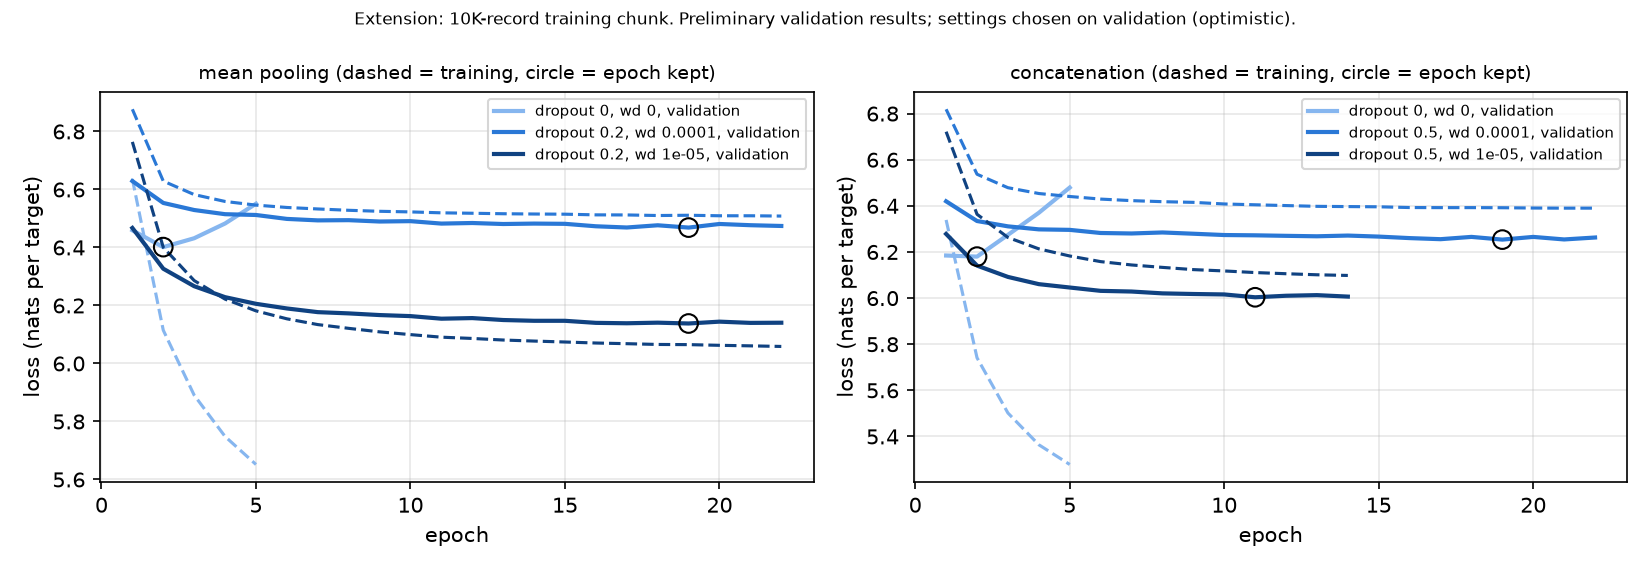

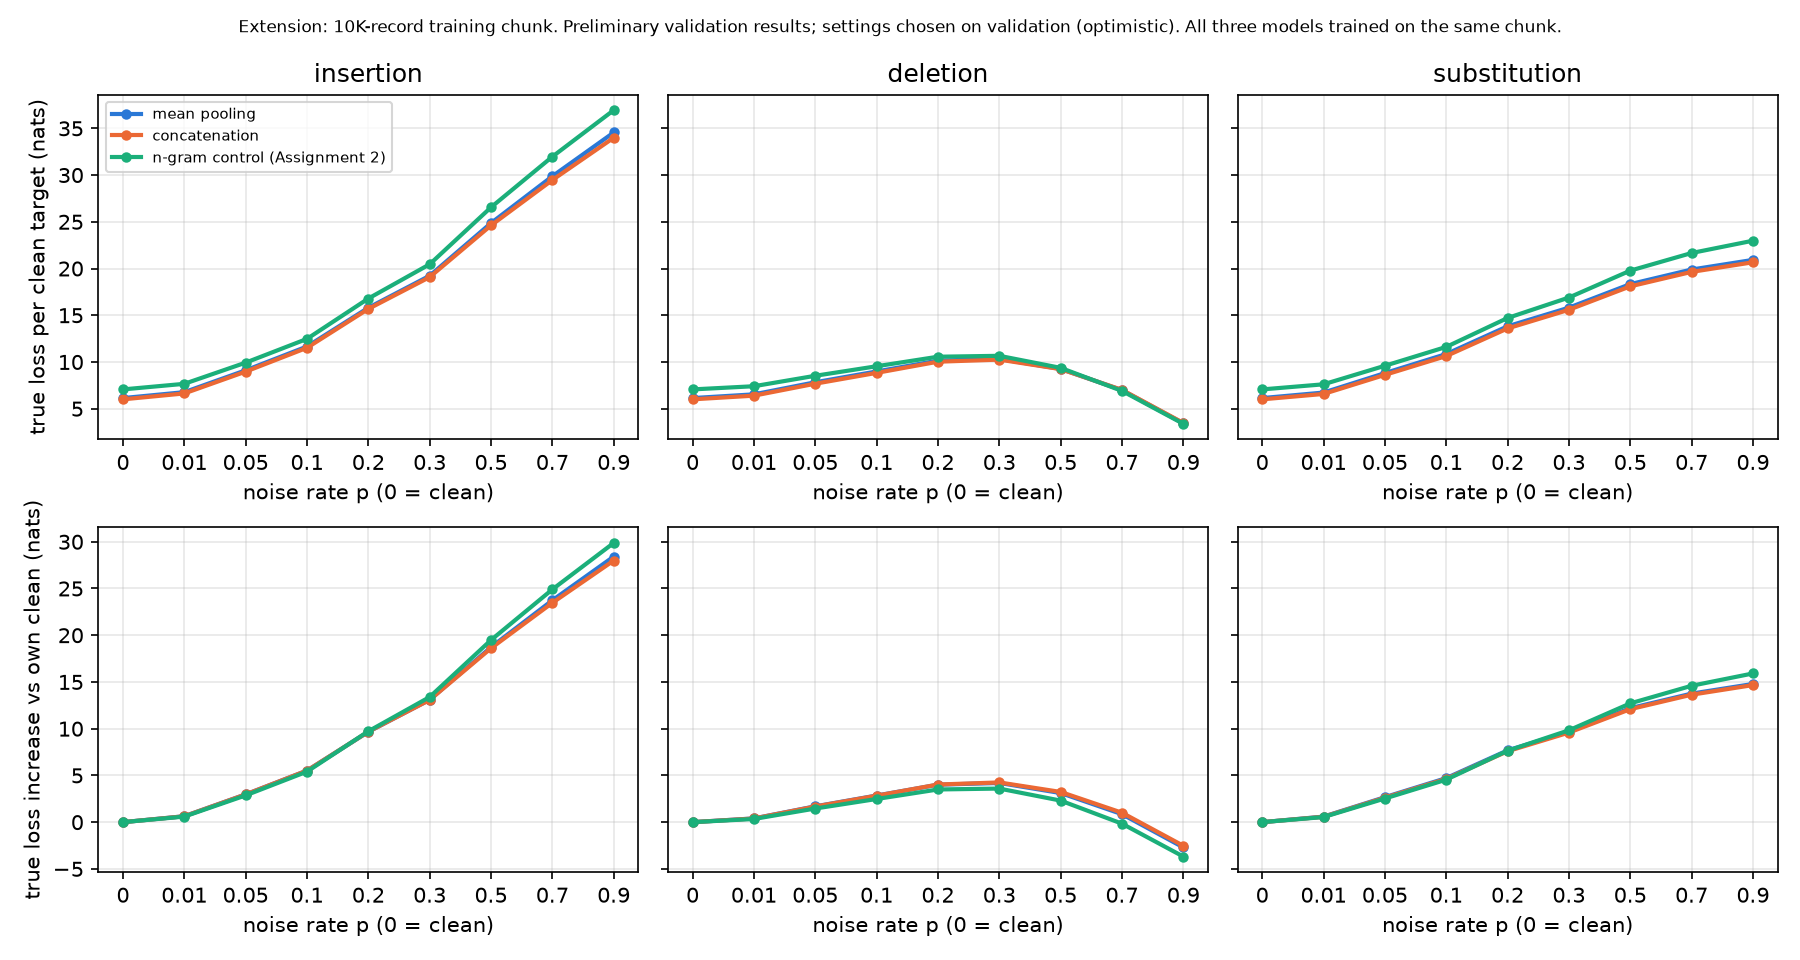

In [63]:
# figures written by the run (learning curves; true loss under noise vs the n-gram trained on the same chunk)
from IPython.display import Image, display
display(Image(filename=str(SC / "figures" / "scale_training.png"))); display(Image(filename=str(SC / "figures" / "scale_noise.png")))

In [64]:
# under noise: true loss of the best networks vs the n-gram trained on the SAME chunk; which noise cells does each win?
k10 = {r: ssum[ssum.run == r].set_index(["operation", "p"]).H_true_mean for r in list(sbest.run) + ["ngram"]}
t10 = pd.DataFrame(k10); t10.columns = [c.split("_")[0] if c != "ngram" else "ngram" for c in t10.columns]
nz10 = t10[t10.index.get_level_values(0) != "clean"]
print("noise cells (of 24) where the network's true loss is below the n-gram's:", {m: int((nz10[m] < nz10.ngram).sum()) for m in ("mean", "concat")})
inc = ssum[ssum.operation != "clean"].pivot_table(index=["operation", "p"], columns="run", values="dH_true_mean", sort=False)
print("\ntrue-loss increase over own clean loss (nats):"); display(inc[list(sbest.run) + ["ngram"]].round(2))
t10.round(2)

noise cells (of 24) where the network's true loss is below the n-gram's: {'mean': 22, 'concat': 22}

true-loss increase over own clean loss (nats):


run                mean_L1_do0.2_wd1e-05  concat_L1_do0.5_wd1e-05  ngram
operation    p                                                          
insertion    0.01                   0.63                     0.63   0.60
             0.05                   2.97                     2.96   2.86
             0.10                   5.52                     5.52   5.41
             0.20                   9.66                     9.67   9.72
             0.30                  13.09                    13.08  13.39
             0.50                  18.73                    18.61  19.49
             0.70                  23.74                    23.47  24.90
             0.90                  28.42                    27.99  29.88
deletion     0.01                   0.40                     0.39   0.34
             0.05                   1.69                     1.67   1.46
             0.10                   2.85                     2.83   2.48
             0.20                   4.01                     4.03   3.50
             0.30                   4.19                     4.25   3.59
             0.50                   3.12                     3.23   2.31
             0.70                   0.85                     1.01  -0.16
             0.90                  -2.70                    -2.53  -3.68
substitution 0.01                   0.59                     0.58   0.55
             0.05                   2.67                     2.62   2.53
             0.10                   4.71                     4.63   4.55
             0.20                   7.68                     7.59   7.64
             0.30                   9.68                     9.58   9.83
             0.50                  12.19                    12.09  12.71
             0.70                  13.75                    13.64  14.59
             0.90                  14.78                    14.67  15.91

mean  concat  ngram
operation    p                         
clean        0.00   6.14    6.00   7.07
insertion    0.01   6.77    6.63   7.66
             0.05   9.11    8.97   9.93
             0.10  11.66   11.52  12.47
             0.20  15.80   15.68  16.79
             0.30  19.23   19.08  20.46
             0.50  24.86   24.61  26.55
             0.70  29.87   29.47  31.97
             0.90  34.55   33.99  36.94
deletion     0.01   6.54    6.40   7.41
             0.05   7.83    7.68   8.52
             0.10   8.99    8.84   9.54
             0.20  10.15   10.03  10.56
             0.30  10.33   10.25  10.66
             0.50   9.25    9.24   9.37
             0.70   6.99    7.01   6.90
             0.90   3.44    3.48   3.38
substitution 0.01   6.73    6.58   7.61
             0.05   8.81    8.62   9.60
             0.10  10.85   10.64  11.61
             0.20  13.82   13.59  14.71
             0.30  15.81   15.59  16.90
             0.50  18.33   18.09  19.77
             0.70  19.89   19.64  21.66
             0.90  20.92   20.67  22.98

**Reading this (extension, preliminary validation results).**

- **More data is the bigger lever.** On the 10K chunk the best networks reach a clean validation loss of **6.00** (concatenation) and **6.14** (mean pooling),
  against 6.78 and 7.02 for the best regularised models on 500 records, and 7.28 and 7.50 for the required Assignment 3 models. Accuracy: 18.2% and 16.5%.
  Only 0.6% of validation targets are now unseen in training (17.0% on the slice).
- **The right amount of regularisation shrinks with more data.** The 500-record winners (weight decay 1e-4) are now *worse* than no regularisation
  (concatenation 6.25 against 6.18; mean 6.47 against 6.40): they hold back a model that has enough data. Weight decay 1e-5 with the same dropout is best for both.
  Without regularisation the networks still peak at epoch 2, but each epoch is now 36× more training steps.
- **The n-gram control gets stronger too.** Rebuilt on the same chunk, its interpolation weights become (0.75, 0.25, 0): it now uses the previous token, where on 500 records it was a unigram.
  Its clean loss drops from 7.55 to 7.07. The networks still beat it on clean text by about a nat.
- **Under noise the networks now win almost everywhere.** Both best networks have a lower true loss than the matched n-gram in **22 of 24** noise cells, including heavy insertion,
  which the n-gram won in every earlier setting. The exceptions are deletion at p = 0.70 and 0.90, the shrinking-text cases of section 20, where all three models sit within 0.11 nats.
- **Unlike regularisation, more data makes the noise penalty smaller.** The increase in true loss over each model's own clean loss falls for concatenation from +31.4 (500 records,
  regularised) to **+28.0** nats at 90% insertion, and from +16.9 to +14.7 at 90% substitution, now below the n-gram's own increase (+29.9 and +15.9).
  At light insertion and substitution (p ≤ 0.20) the increases are about the same for all three models; under deletion the networks' increase is about 0.5 nats larger than the n-gram's at p = 0.20.
- Training loss (dashed) sits *above* validation loss for the regularised runs because dropout is switched on while training loss is measured.
- **Caveats.** Settings were chosen on the validation records they are reported on (optimistic). Each run was trained once. The `seconds` column is wall-clock time and includes
  periods when the laptop was asleep, so it is not a speed measurement (the last concatenation run especially).

### 25b. Depth on the 10K chunk (R2b)

On 500 records extra hidden layers only overfit faster (sections 22 and 24). With 36× more data there may be enough to use them. Each model's best 10K setting
(dropout as in R1, weight decay 1e-5) is re-trained at 2 and 3 hidden layers of width 64; the 1-layer result is the R2 run itself (same settings and seed), reused rather than re-trained.
Run: `python phase3_extensions.py scale --depth-only`.

In [65]:
dr = pd.read_csv(SC / "scale_depth_runs.csv"); dsum = pd.read_csv(SC / "scale_depth_noise_summary.csv")
print(dr[["model", "n_layers", "dropout", "weight_decay", "trainable", "epochs_run", "best_epoch", "best_val_loss", "val_acc_at_best"]].round(4).to_string(index=False))
k = dsum[(dsum.operation != "clean") & dsum.p.isin([0.2, 0.5, 0.9])]
k.pivot_table(index=["operation", "p"], columns=["model", "n_layers"], values="dH_true_mean", sort=False).round(2)

 model  n_layers  dropout  weight_decay  trainable  epochs_run  best_epoch  best_val_loss  val_acc_at_best
concat         1      0.5           0.0    2017493          14          11         6.0036           0.1824
concat         2      0.5           0.0    2021653          14          11         6.1536           0.1718
concat         3      0.5           0.0    2025813          15          12         6.2586           0.1579
  mean         1      0.2           0.0    1968341          22          19         6.1379           0.1645
  mean         2      0.2           0.0    1972501          22          19         6.1187           0.1657
  mean         3      0.2           0.0    1976661          22          19         6.1755           0.1636


model            concat                 mean              
n_layers              1      2      3      1      2      3
operation    p                                            
insertion    0.2   9.67   9.43   9.48   9.66   9.62   9.57
             0.5  18.61  18.20  18.37  18.73  18.65  18.59
             0.9  27.99  27.41  27.69  28.42  28.29  28.24
deletion     0.2   4.03   3.86   3.79   4.01   4.03   3.96
             0.5   3.23   2.99   2.88   3.12   3.17   3.04
             0.9  -2.53  -2.77  -2.84  -2.70  -2.66  -2.78
substitution 0.2   7.59   7.39   7.41   7.68   7.63   7.57
             0.5  12.09  11.84  11.93  12.19  12.11  12.08
             0.9  14.67  14.46  14.64  14.78  14.68  14.75

**Reading this (extension, preliminary validation results).**

- **More data does not make depth pay off for concatenation.** Its best clean validation loss gets worse with each layer: **6.004 / 6.154 / 6.259** for 1 / 2 / 3 layers (accuracy 18.2% / 17.2% / 15.8%).
- **Mean pooling gains a little from a second layer**: **6.138 / 6.119 / 6.176**. This is the first time an extra layer has helped in any experiment (on 500 records every extra layer was worse), but 0.02 nats is small and the third layer loses it again.
- **Under heavy noise the 2-layer concatenation model is slightly better** despite its worse clean loss: true loss at 90% insertion 33.56 against 33.99 for 1 layer, 90% substitution 20.62 against 20.67. Its increase over its own clean loss is smaller at every insertion and substitution rate (27.41 against 27.99 at 90% insertion), partly because it starts from a higher clean loss. All differences are under 0.5 nats.
- Against the n-gram trained on the same chunk, the 2- and 3-layer concatenation models win 23 of 24 noise cells (1 layer: 22); mean pooling wins 22 at every depth.
- **Caveats.** The regularisation was tuned at 1 layer (dropout as in R1, weight decay 1e-5) and not re-tuned for the deeper networks, which might prefer other values. Each depth was trained once. The 1-layer rows are the R2 runs, reused.
- **Conclusion across all depth experiments:** with 500 records depth always hurt; with 10K records it is neutral to slightly harmful on clean text, with a small gain under heavy noise. More data and the right amount of regularisation matter far more than depth for these networks.

## 26. Which network next?

**Recommendation: the pretrained BERT encoder itself, frozen. Not a transformer or an RNN trained from scratch.**

- The project brief asks how noise affects *masked-encoder representations*, and Assignment 3 lists contextual transformer experiments as the next step.
- Any network we train ourselves on 500 records overfits the same way these do (best at epoch 2, section 22). BERT is already trained, so we only run it: no training budget, no new overfitting.
- It extends both workstreams. Geometry becomes clean/noisy cosine at each of BERT's 12 layers; the static table **E** used here is layer 0, so the curves connect.
  Prediction becomes masked-token cross-entropy (pseudo-perplexity, which the brief says not to call perplexity).
- An optional cheap step first: widen the FFNN context from 2 to 4 or 8 tokens. It asks whether more context helps or just gives noise more to break, which is the question BERT's full-sentence context raises.
  An LSTM is the textbook step in between, but it would face the same 500-record limit and add little to the research question.